# Modulreihe KI: Machine Learning & Deep Learning Sommersemester 2026

## Projekteinleitung: Ein datenbasiertes Frühwarnsystem für Studierende

### Projektkontext

| | |
|---|---|
| **Autor (Regressionsteil)** | Mares Büchler |
| **Projektform** | Partnerarbeit, dieses Notebook umfasst den eigenverantwortlich umgesetzten Regressionsteil |
| **Studiengang** | Wirtschaftsinformatik (B.Sc.), 4. Fachsemester |
| **Semester** | Sommersemester 2026 |
| **Modulreihe** | KI: Machine Learning & Deep Learning |

Diese Arbeit deckt gebündelt die drei Module AIML, KI: Machine Learning und KI: Deep Learning ab. Grundlage ist durchgängig ein Datensatz (`Student_Performance.csv`, $\approx 25.000$ Studierende), auf den drei unterschiedliche Analyseverfahren angewendet werden.

### Problemstellung & Ausgangslage

Hochschulen erkennen leistungsgefährdete Studierende häufig erst dann, wenn Prüfungen bereits nicht bestanden sind, also zu spät für gezieltes Gegensteuern. Gleichzeitig liegen zahlreiche **früh verfügbare Merkmale** vor (Lernzeit, Anwesenheit, Bildungshintergrund der Eltern, Lernmethode etc.), die einen Hinweis auf die spätere Leistung geben könnten.

Daraus ergibt sich das leitende Erkenntnisinteresse und die **Leitfrage** dieses Projekts:

> **Lassen sich Studierende anhand früh verfügbarer Merkmale zuverlässig in ihrer Leistung einschätzen?**

Diese Fragestellung wird bewusst nicht durch ein einzelnes Modell beantwortet, sondern aus **drei komplementären Blickwinkeln** beleuchtet, deren Ergebnisse in den jeweiligen Interpretationsabschnitten zusammengeführt werden.

### Ansatz & Ziel: Ein Frühwarnsystem aus drei Perspektiven

Der gemeinsame Anwendungsrahmen aller drei Teilanalysen ist ein **Frühwarnsystem**, das Hochschulen dabei unterstützt, Förderressourcen (z. B. Tutorien) gezielt dort einzusetzen, wo ein Risiko besteht. Jedes Verfahren beleuchtet eine andere Facette derselben Frage:

- **Regression: wie stark?**  (Zielvariable: `overall_score` auf der Skala $[0, 100]$)
  Ein neuronales Netz sagt den **exakten Leistungsscore** voraus. Der metrische Score ist die feinste Auflösung des Leistungsstands und bildet das **Fundament** des Systems: Aus ihm lässt sich jede beliebige Risikoschwelle ableiten, ohne Information zu verlieren.

- **Klassifikation: welche Risikoklasse?**  (abgeleitete Zielvariable: `y_clf`)
  Der Score wird über feste Schwellen in vier Risikoklassen eingeteilt ($0 =$ kein Risiko bis $3 =$ höchstes Risiko). Ein **eigenständiges** neuronales Netz ordnet jeden Studierenden direkt anhand seiner Merkmale einer dieser Klassen zu. Entscheidend: Dieses Netz nutzt nicht die Vorhersage des Regressionsmodells als Eingabe, sondern lernt unabhängig auf denselben Merkmalen. Die Klassifikation ist damit die **operative Ampel** des Frühwarnsystems und macht die Einschätzung unmittelbar handlungsleitend.

- **Clustering: welcher Typ?**  (unüberwacht, ohne Noten)
  Mittels $k$-Means, einer **Self-Organizing Map (SOM)** und **DBSCAN** wird geprüft, ob sich die Studierendenschaft ohne Kenntnis der Noten in abgrenzbare, **datenbasierte Lern-Profile** unterteilen lässt. Dieser Blickwinkel liefert den **Kontext hinter den Merkmalen**: Er zeigt, welche Struktur der Datensatz aus sich heraus trägt, unabhängig vom Leistungsrisiko.

**Metrische Basis, abgeleitete Klassen.** Nach Rücksprache mit Prof. Schneider bildet bewusst die metrische Regression die Grundlage des Systems und nicht eine vorab festgelegte Klasseneinteilung. Der Grund ist ein Informationsargument: Ein metrischer Score lässt sich jederzeit an einer frei wählbaren Schwelle in Klassen zerlegen, während eine vorzeitige Zerlegung in feste Klassen die feine Abstufung unwiederbringlich verwirft. Die Risikoklassen (`y_clf`) werden deshalb nachträglich aus dem Score abgeleitet. Das Klassifikationsmodell selbst bleibt davon getrennt: Es wird als eigenständiges Netz direkt auf den Merkmalen trainiert und greift nicht auf die Regression zurück.

### Projektablauf: Aufbau der Notebooks

Alle drei Analysen teilen sich diesen **identischen Master-Teil** als Ausgangslage. Er ist jedem Notebook wortgleich vorangestellt:

1. **Master-Teil (dieser Abschnitt):** Einlesen, Bereinigung, Encoding, explorative Analyse sowie einheitliche Partitionierung und Zuordnung der Datensätze. Dieser Teil ist **allgemeingültig und in allen drei Notebooks gleich**.
2. **Modellspezifischer Teil:** Erst danach folgt das jeweilige Verfahren: Modellaufbau, Training, Auswertung und **detaillierte Interpretation** der Ergebnisse.

Die beiden neuronalen Netze (Regression und Klassifikation) folgen dabei demselben schrittweisen **Baukastenprinzip**:

- **Baseline-Modell:** ein bewusst kleines Netz, um das grundlegende Verhalten einzuschätzen.
- **Tiefes Modell:** erweiterte Architektur zur Steigerung der Güte.
- **Optimiertes Modell:** finale Auswahl nach **Hyperparameteroptimierung**.

Das Clustering nutzt einen eigenen, verfahrensspezifischen Aufbau ($k$-Means, SOM, DBSCAN).

### Hinweis zur Wiederverwendung

Dieses Projekt baut auf einer **vorangegangenen Regressions-Analyse von Mares Büchler** aus dem zuvor belegten Modul *Grundlagen der Datenanalyse* auf. Der Datensatz `Student_Performance.csv` sowie ein Großteil der Datenvorverarbeitung wurden aus dieser Arbeit **übernommen und weiterentwickelt**.


### Hinweis zu diesem Notebook
Dieses Notebook enthält den gemeinsamen Master-Teil sowie den vollständigen Regressionsteil. Die **Teilanalysen Klassifikation** und **Clustering** wurden von einem weiteren Gruppenmitglied umgesetzt und sind **nicht Teil dieses Repositorys**. Verweise darauf dienen nur der Einordnung in das Gesamtprojekt.

---

## Reset der Arbeitsumgebung

Möglichkeit zur vollständigen Zurücksetzung der Arbeitsumgebung mit `%reset -f`. Somit werden alle zuvor definierten Variablen aus dem Arbeitsspeicher entfernt.

In [2]:
%reset -f

## Modulimporte

In [3]:
# System und Reproduzierbarkeit: Standardbibliotheken von Python(zum Fixieren aller Zufallsquellen, damit jeder Lauf reproduzierbar bleibt)
import os
import random

# Standard-Bibliotheken für Datenmanagement: Grundgerüst zum Einlesen, Umformen und Berechnen der Daten.
import numpy as np
import pandas as pd

# Machine Learning und Preprocessing (Scikit-Learn): Werkzeuge zum Aufteilen und Skalieren der Daten, ein lineares Vergleichsmodell sowie die Gütemetriken.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Deep Learning Framework (TensorFlow und Keras): Basis für Aufbau, Training und Auswertung der neuronalen Netze.
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import plot_model

# Visualisierung und Grafikausgabe: Bibliotheken zur grafischen Darstellung von Daten und Ergebnissen (Heatmap, Lernkurven, Boxplots etc.).
import seaborn as sns
import matplotlib.pyplot as plt

# Einstellung für die Grafikausgabe: Grafiken werden direkt im Notebook angezeigt
%matplotlib inline

# Optionale Einstellung: Verbesserte Lesbarkeit der Diagramme (einheitliches Design)
sns.set_theme(style="whitegrid")

# Prüfung auf erfolgreiche Modul-Importe
print("Erfolgreicher Modulimport!")
print(f"TensorFlow Version: {tf.__version__} erfolgreich geladen.")

Erfolgreicher Modulimport!
TensorFlow Version: 2.21.0 erfolgreich geladen.


## Reproduzierbarkeit: Globaler Seed

Damit jeder Trainingslauf identische Ergebnisse liefert, werden alle Zufallsquellen zentral fixiert. Das gilt als Voraussetzung für einen fairen Modellvergleich.

Neuronale Netze initialisieren ihre Gewichte zufällig und mischen die Trainingsdaten in zufälliger Reihenfolge. Ohne festen Seed liefert deshalb jeder Lauf leicht andere Zahlen und die Ergebnisse wären nicht reproduzierbar. Der Seed wird daher an einer zentralen Stelle für alle relevanten Zufallsquellen gesetzt: Python, NumPy und TensorFlow.

In [4]:
# Globaler Seed = 42
SEED = 42

tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
os.environ['PYTHONHASHSEED'] = str(SEED)   # Python-Hash-Seed
random.seed(SEED)                          # Python-eigener Zufall
np.random.seed(SEED)                       # NumPy
tf.random.set_seed(SEED)                   # TensorFlow/Keras

print(f"Globaler Seed auf {SEED} gesetzt (Gewichtsinitialisierung, Splits und Shuffling reproduzierbar).")

Globaler Seed auf 42 gesetzt (Gewichtsinitialisierung, Splits und Shuffling reproduzierbar).


## Laden und Formatierung der Daten

Der Datensatz `Student_Performance.csv` enthält Informationen über 25.000 Schüler, deren Lerngewohnheiten, Bildungsstand der Eltern und akademische Leistungen.

* `overall_score`: Durchschnittliche Punktzahl über alle Fächer [0-100 Punkte] -> **Zielvariable**
* `student_id`: Eindeutige Identifikationsnummer des Schülers [Primärschlüssel: gelöscht, da keinen Nutzen für ML]
* `age`: Alter des Schülers [Jahre]
* `gender`: Geschlecht [male, female, other]
* `school_type`: Art der Schule [public, private]
* `parent_education`: Höchster Bildungsabschluss der Eltern [no formal, high school, diploma, graduate, post graduate, phd]
* `study_hours`: Täglich aufgewendete Zeit für das Selbststudium [Stunden]
* `attendance_percentage`: Anwesenheitsquote im Unterricht [0-100%]
* `internet_access`: Verfügbarkeit von Internetzugang [no, yes]
* `travel_time`: Zeitaufwand für den Schulweg [<15 min, 15-30 min, 30-60 min, >60 min]
* `extra_activities`: Teilnahme an außerschulischen Aktivitäten [no, yes]
* `study_method`: Bevorzugte Lernmethode [notes, textbook, group study, coaching, mixed, online videos]
* `math_score` / `science_score` / `english_score`: Einzelnoten in den Fachbereichen [0-100 Punkte]
* `final_grade`: Zusammenfassende Note als Kategorie [a bis f]

**Hinweis zur Formatierung:** In den folgenden Abschnitten wird der Datensatz eingelesen und bereinigt. Um die Analyse zu erleichtern, wird die Zielvariable (`overall_score`) an die erste Stelle des Datensatzes verschoben.

Ein wichtiger Schritt ist die Vorbereitung der kategorischen Variablen, also der Merkmale, die ursprünglich als Text vorliegen. Dabei werden zwei Arten unterschieden:

* **Ordinale Merkmale** besitzen eine logische Rangfolge (zum Beispiel der Bildungsabschluss der Eltern oder die Wegzeit). Sie werden direkt in aufsteigende Zahlenwerte übersetzt, sodass die Reihenfolge für das Modell erhalten bleibt.
* **Nominale Merkmale** besitzen keine Rangfolge (zum Beispiel Geschlecht oder Lernmethode). Sie werden zunächst ausdrücklich als Text (String) deklariert. Dadurch werden sie im späteren Preprocessing automatisch per One-Hot-Encoding in einzelne 0/1-Spalten umgewandelt.

Datenquelle: [Student Performance Dataset auf Kaggle.com](https://www.kaggle.com/datasets/kundanbedmutha/student-performance-dataset?resource=download)

In [5]:
# Datensatz aus der CSV-Datei einlesen
df = pd.read_csv("Student_Performance.csv")

# Spalten umordnen: Zielvariable 'overall_score' (Index 14) an die erste Stelle holen (dient zur besseren Übersicht)
df = df.iloc[:, np.r_[14, 0:14, 15]]

# Bereinigung: 'student_id' entfernen (ohne Nutzen)
df.drop(columns=['student_id'], inplace=True, errors='ignore')

# Ordinal Encoding: Merkmale mit logischer Rangfolge in aufsteigende Zahlen übersetzen
parent_edu_map = {
    'no formal': 0,
    'high school': 1,
    'diploma': 2,
    'graduate': 3,
    'post graduate': 4,
    'phd': 5
}

travel_time_map = {
    '<15 min': 0,
    '15-30 min': 1,
    '30-60 min': 2,
    '>60 min': 3
}

df['parent_education'] = df['parent_education'].map(parent_edu_map)
df['travel_time'] = df['travel_time'].map(travel_time_map)

# Nominal Deklaration: Merkmale ohne Rangfolge als String erzwingen, damit sie im Preprocessing automatisch per One-Hot-Encoding (0/1-Spalten) verarbeitet werden
nominal_cols = ['gender', 'school_type', 'internet_access', 'extra_activities', 'study_method']
for col in nominal_cols:
    df[col] = df[col].astype(str)

# Anzeige der ersten 5 Zeilen zur Überprüfung der neuen Struktur
df.head()

,overall_score,age,gender,school_type,parent_education,study_hours,attendance_percentage,internet_access,travel_time,extra_activities,study_method,math_score,science_score,english_score,final_grade
0,53.1,14,male,public,4,3.1,84.3,yes,0,yes,notes,42.7,55.4,57.0,e
1,61.3,18,female,public,3,3.7,87.8,yes,3,no,textbook,57.6,68.8,64.8,d
2,89.6,17,female,private,4,7.9,65.5,no,0,no,notes,84.8,95.0,79.2,b
3,41.6,16,other,public,1,1.1,58.1,no,1,no,notes,44.4,27.5,54.7,e
4,25.4,16,female,public,1,1.3,61.0,yes,2,yes,group study,8.9,32.7,30.0,f


## Datenvorverarbeitung

### Umgang mit fehlenden Werten (Missing Values)

Prüfung auf **fehlenden Werte** in allen Spalten des Datensatzes.

**Ergebnis:** Der Datensatz wurde erfolgreich geprüft und weist **keine fehlenden Werte** auf.

In [6]:
# Prüfung auf fehlende Werte in allen Spalten
missing_values = df.isnull().sum()

if missing_values.sum() > 0:
    print("Es wurden folgende Anzahl fehlender Werte pro Spalte ermittelt. ")
else:
    print("Es wurden keine fehlenden Werte im Datensatz gefunden.")

# Ausgabe der Ergebnisse
print("\nAnzahl fehlender Werte pro Spalte:\n")
print(missing_values)

Es wurden keine fehlenden Werte im Datensatz gefunden.

Anzahl fehlender Werte pro Spalte:

overall_score            0
age                      0
gender                   0
school_type              0
parent_education         0
study_hours              0
attendance_percentage    0
internet_access          0
travel_time              0
extra_activities         0
study_method             0
math_score               0
science_score            0
english_score            0
final_grade              0
dtype: int64


### Untersuchung auf Ausreißer (Outliers)

Um die Zuverlässigkeit der Ergebnisse sicherzustellen, wurde der Datensatz auf Ausreißer untersucht. Hierzu wurden für die zentralen numerischen Variablen Boxplots erstellt, konkret für den Lernerfolg (`overall_score`), die Lernzeit (`study_hours`) und die Anwesenheit (`attendance_percentage`). Diese Methode erlaubt es, extreme Abweichungen visuell zu identifizieren, die das spätere Modell verzerren könnten.

**Zusammenfassung der Ergebnisse:**

* **Homogenität:** Der Datensatz erweist sich als sehr homogen und sauber. Es finden sich keine unplausiblen Extremfälle, wie beispielsweise Schüler, die ohne jeglichen Lernaufwand eine maximale Punktzahl erzielen, oder Schüler, die trotz lückenloser Anwesenheit völlig scheitern.
* **Logische Plausibilität:** Alle beobachteten Datenpunkte liegen innerhalb eines logisch nachvollziehbaren Rahmens (z. B. Scores zwischen 0 und 100 Punkten). Es gibt daher keine Anzeichen für Messfehler oder fehlerhafte Dateneingaben.
* **Vorteil für das Modell:** Da keine signifikanten Ausreißer existieren, ist von einer hohen Stabilität während des Modelltrainings auszugehen. Gerade gradientenbasiert trainierte neuronale Netze profitieren von solchen fehlerfreien Verteilungen.

**Interpretation:**
Da sich alle Werte innerhalb des statistisch erwartbaren Bereichs befinden, ist keine manuelle Bereinigung oder Eliminierung von Datensätzen erforderlich. Der vollständige Datensatz von 25.000 Beobachtungen wird im weiteren Verlauf beibehalten.

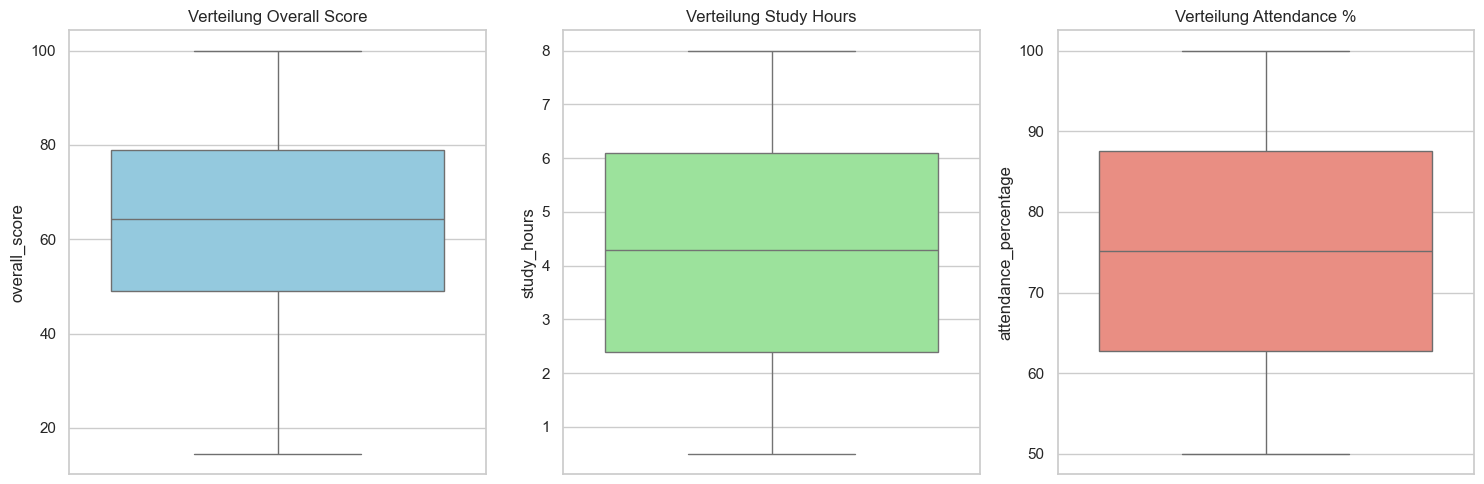

In [7]:
# Erstellung von drei Boxplots zur visuellen Ausreißer-Analyse
plt.figure(figsize=(15, 5))

# Boxplot für die Zielvariable (Overall Score)
plt.subplot(1, 3, 1) 
sns.boxplot(y=df['overall_score'], color='skyblue')
plt.title('Verteilung Overall Score')

# Boxplot für die Lernstunden (Study Hours)
plt.subplot(1, 3, 2)
sns.boxplot(y=df['study_hours'], color='lightgreen')
plt.title('Verteilung Study Hours')

# Boxplot für die Anwesenheit (Attendance Percentage)
plt.subplot(1, 3, 3)
sns.boxplot(y=df['attendance_percentage'], color='salmon')
plt.title('Verteilung Attendance %')

plt.tight_layout()
plt.show()

# Methodische Erklärungen für das Team-Verständnis:
# plt.subplot(Reihen, Spalten, Index): Definiert die Position des aktuellen Diagramms im Raster.
# Die Box: Repräsentiert den Interquartilsabstand (IQR). Hier liegen die mittleren 50 % aller Daten.
# Der Strich in der Box: Zeigt den Median (den genauen Mittelwert der nach Größe sortierten Daten).
# Ausreißer: Würden als einzelne Punkte außerhalb der vertikalen Linien (Whiskers) dargestellt werden. Da der Datensatz extrem sauber ist, sind hier keine Punkte zu sehen.

## Explorative Datenanalyse: Korrelationen und Heatmap

Bevor die eigentliche Modellierung beginnt, werden zunächst die linearen Zusammenhänge (Pearson-Korrelation) zwischen den numerischen Variablen untersucht.

**Vermeidung von Data Leakage:**
Um ein realistisches Bild der tatsächlichen Einflussfaktoren zu erhalten, werden Variablen, die die Zielgröße (`overall_score`) direkt berechnen (wie die Teilnoten `math_score`, `science_score`, `english_score`), bewusst aus der Analyse ausgeschlossen. Auch die späteren Modelle erhalten diese Informationen im weiteren Verlauf nicht als Eingabe.

**Ziel der Analyse:**
Die Korrelationsmatrix hilft zu verstehen, welche soziodemografischen Faktoren (wie z. B. die elterliche Bildung, die durch das zuvor durchgeführte Ordinal-Encoding nun messbar ist) oder Verhaltensweisen (wie die Lernzeit) den stärksten isolierten Einfluss auf den Lernerfolg haben.

### Visualisierung als Heatmap

Zur besseren Übersichtlichkeit wird diese Matrix als Heatmap in einem weiteren Schritt visualisiert. Die Koeffizienten bewegen sich theoretisch in einem Bereich von $-1$ (perfekt negativer Zusammenhang) bis $+1$ (perfekt positiver Zusammenhang).

**Hinweis zur Skalierung:**
Beim Aufruf von `seaborn` wird bewusst kein fester Wertebereich für die Farben vorgegeben. Die Bibliothek wählt die Farbgrenzen daher automatisch anhand des kleinsten und größten Werts der Matrix. Da im vorliegenden Datensatz keine nennenswerten negativen Korrelationen existieren, erstreckt sich die Farbskala im Ergebnis praktisch nur über den positiven Bereich (ein Beispiel für einen negativen Zusammenhang wäre: „Je mehr ein Schüler lernt, desto schlechter fällt die Note aus").

* **Minimalwert:** Der kleinste Korrelationswert im bereinigten Datensatz liegt bei $\approx -0,0065$ und damit extrem nah an der Nullgrenze.
* **Maximalwert:** Der Koeffizient von $1,00$ beschreibt die Korrelation einer Variable mit sich selbst.
* **Optische Hervorhebung:** Durch die automatische Anpassung der Farbgrenzen an die reale Datenstruktur werden die feinen Unterschiede in den positiven Zusammenhängen deutlich besser sichtbar.

**Erste Erkenntnisse:**
Schon in dieser explorativen Phase lassen sich zwei wesentliche Treiber für den `overall_score` identifizieren:
1. **Haupttreiber:** Es besteht eine extrem starke Korrelation ($0,91$) zu den Lernstunden (`study_hours`). Die aktive Eigenleistung hat somit den linear stärksten Einfluss auf das Endergebnis.
2. **Sekundärer Treiber:** Die Anwesenheitsquote (`attendance_percentage`) zeigt mit $0,29$ ebenfalls einen messbaren, wenngleich moderateren positiven Effekt.

Alle anderen Hintergrundfaktoren fallen linear kaum ins Gewicht. In den folgenden Analysen wird jedoch geprüft, ob sich in diesen unscheinbaren Variablen (wie z.B. der elterlichen Bildung) tiefere, nicht-lineare Muster oder Strukturen finden lassen.

In [8]:
# Korrelationsmatrix & Visualisierung als Heatmap
# Auswahl numerischer Spalten
# Dank des Encodings sind 'parent_education' & 'travel_time' dabei. Text-Strings werden bewusst ignoriert.
numeric_df = df.select_dtypes(include=[np.number])

# Vermeidung von Data Leakage (Teilnoten entfernen)
leakage_cols = ['math_score', 'science_score', 'english_score']
numeric_df_clean = numeric_df.drop(columns=leakage_cols, errors='ignore')

# Berechnung der Korrelationsmatrix
corr_matrix = numeric_df_clean.corr()

# Berechnung der Minimal- und Maximalwerte
min_corr = corr_matrix.values.min()
max_corr = corr_matrix.values.max()

print(f"Der kleinste Korrelationswert im Datensatz beträgt: {min_corr:.4f}")
print(f"Der größte Korrelationswert im Datensatz beträgt: {max_corr:.4f}\n")

print("Bereinigte Korrelationsmatrix:")
display(corr_matrix)

Der kleinste Korrelationswert im Datensatz beträgt: -0.0065
Der größte Korrelationswert im Datensatz beträgt: 1.0000

Bereinigte Korrelationsmatrix:


,overall_score,age,parent_education,study_hours,attendance_percentage,travel_time
overall_score,1.000000,-0.003847,0.002692,0.905771,0.292762,-0.004534
age,-0.003847,1.000000,0.002755,-0.003722,0.006050,0.005039
parent_education,0.002692,0.002755,1.000000,0.006785,-0.003380,-0.005651
study_hours,0.905771,-0.003722,0.006785,1.000000,-0.005046,-0.006530
attendance_percentage,0.292762,0.006050,-0.003380,-0.005046,1.000000,-0.000913
travel_time,-0.004534,0.005039,-0.005651,-0.006530,-0.000913,1.000000


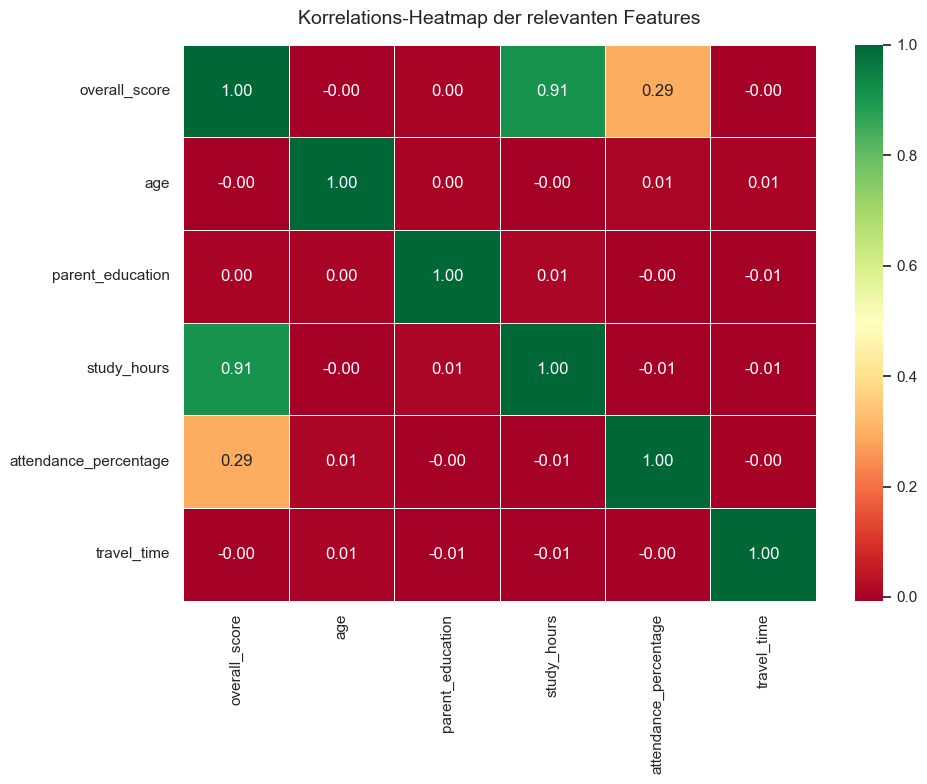

In [9]:
# Visualisierung als Korrelations-Heatmap
plt.figure(figsize=(10, 8))

# Seaborn wird bewusst die Farbskalierung überlassen (kein vmin/vmax festgelegt), damit die feinen positiven Unterschiede optimal hervortreten.
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', fmt=".2f", linewidths=0.5)

plt.title('Korrelations-Heatmap der relevanten Features', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## Partitionieren der Datenmenge in Trainings- und Testdatensatz

### Unified Data Preprocessing und Partitionierung

Um eine konsistente Datenbasis für die drei folgenden Teilanalysen (Regression, Klassifikation und Clustering) zu schaffen, wird eine zentrale Vorverarbeitungs-Pipeline implementiert. Dabei werden methodische Standards des Machine Learning berücksichtigt, damit die aufbereiteten Merkmale von allen drei Verfahren unmittelbar genutzt werden können.

**Vermeidung von Data Leakage**
Um die Integrität der Modelle sicherzustellen, werden alle Features entfernt, die bereits Informationen über das Zielergebnis enthalten (z. B. Teilnoten wie `math_score` oder die Endnote `final_grade`). Die Modelle lernen somit ausschließlich auf Basis der soziodemografischen Hintergrunddaten und des Lernverhaltens.

**Differenziertes Encoding (Nominal vs. Ordinal)**
Um den Informationsgehalt der Merkmale bestmöglich zu erhalten, werden zwei Encoding-Strategien unterschieden:

1. **Ordinal Encoding (Rangfolgen-Erhaltung):** Merkmale mit einer logischen Hierarchie (z. B. elterliche Bildung oder Schulweg-Dauer) werden über ein Mapping $\phi: \mathcal{C} \to \mathbb{N}_0$ in aufsteigende Zahlenwerte transformiert:
   $$\text{parent\_education} \in \{ \text{no formal} < \dots < \text{phd} \} \xrightarrow{\text{Mapping}} \{0, \dots, 5\}$$

2. **Nominal Encoding (One-Hot-Verfahren / Dummifizierung):** Merkmale ohne natürliche Rangfolge (z. B. Geschlecht, Lernmethode) können von neuronalen Netzen nicht im Textformat verarbeitet werden. Mittels `pd.get_dummies()` werden diese Kategorien in binäre Dummy-Variablen $x_k \in \{0, 1\}$ umgewandelt.

   * **Vermeidung der Dummy-Variable-Trap:** Durch den Parameter `drop_first=True` wird die erste Ausprägung jeder Kategorie bewusst als Referenzgruppe ($n-1$ Regel) ausgeschlossen. Dies verhindert perfekte Multikollinearität (redundante Informationen) und sichert die mathematische Stabilität bei der späteren Gewichtsoptimierung.

**Datenpartitionierung (Train-Test-Split)**
Der Datensatz wird in einen **Trainingsdatensatz (80 %)** und einen **Testdatensatz (20 %)** unterteilt. Durch einen fixierten `random_state=42` wird sichergestellt, dass die Aufteilung für alle Analysen identisch ist und die Ergebnisse dadurch vergleichbar bleiben. Der Testdatensatz bleibt ein unberührtes Hold-out und wird erst für die finale Bewertung angefasst. Die weitere Unterteilung des Trainingsblocks in Training und Validierung erfolgt bewusst erst im jeweiligen Modellabschnitt, da sie modellspezifisch ist.

**Duale Zielgrößen (Targets)**
Für die beiden überwachten Verfahren werden zwei getrennte Zielgrößen vorbereitet. Das Clustering benötigt keine Zielgröße, da es unüberwacht ausschließlich auf den Merkmalen arbeitet.
* **Regression ($y_{reg}$):** Der kontinuierliche `overall_score` zur Vorhersage der exakten Punktzahl.
* **Klassifikation ($y_{clf}$):** Eine Diskretisierung des Scores in vier Risiko-Klassen (stark gefährdet bis kein Risiko).

**Globale Skalierung (Standardisierung)**
Da neuronale Netze empfindlich auf unterschiedliche Wertebereiche reagieren, werden **alle** Features mittels Z-Transformation standardisiert:

$$z = \frac{x - \mu}{\sigma}$$

Dabei ist:
* $z$: der skalierte Wert
* $x$: der ursprüngliche Messwert
* $\mu$: der Mittelwert der Daten
* $\sigma$: die Standardabweichung

Hinweis: Auch die binären Dummy-Variablen werden mitskaliert. Das verbessert die Stabilität des Gradientenabstiegs in tiefen Netzen und sorgt zugleich dafür, dass kein Merkmal allein aufgrund seines Wertebereichs überproportionalen Einfluss erhält.

In [10]:
# Spalten selektieren und Data Leakage verhindern
target_metric = 'overall_score'
leakage_columns = ['math_score', 'science_score', 'english_score', 'final_grade', 'student_id']
X_raw = df.drop(columns=[target_metric] + leakage_columns, errors='ignore')

# Globales One-Hot-Encoding für alle kategorischen Merkmale
X_encoded = pd.get_dummies(X_raw, drop_first=True)  # neue Pandas-Version: True/False (Speichereffizienz)
# X_encoded = pd.get_dummies(X_raw, drop_first=True, dtype=int)  # Variante mit 0/1 statt True/False (Alternative zur Veranschaulichung)

# Duale Zielgrößen (Targets) vorbereiten

# 1.) Regressionsmodell: Vorhersage der exakten Punktzahl
y_reg = df[target_metric].values

# 2.) Klassifikationsmodell: Vorhersage von 4 Risiko-Stufen
# Bins: 0-40 (stark gefährdet), 40-55 (leicht), 55-75 (unwahrscheinlich), 75-100 (kein Risiko)
bins = [0, 40, 55, 75, 100]
labels = [3, 2, 1, 0]  # 3 = höchstes Risiko, 0 = geringstes Risiko
y_clf = pd.cut(df[target_metric], bins=bins, labels=labels).astype(int).values

# Gemeinsamer Train-Test-Split (random_state=SEED synchronisiert die Aufteilung für alle Analysen)
X_train_raw, X_test_raw, y_train_reg, y_test_reg, y_train_clf, y_test_clf = train_test_split(
    X_encoded, y_reg, y_clf, test_size=0.2, random_state=SEED)

# Skalierung (Standardisierung) des gesamten Feature-Arrays
# Die Z-Transformation zentriert alle Features (auch die 0/1-Dummies) um den Mittelwert 0.
# Resultat: Fast alle Werte liegen nun auf einer Skala zwischen -3.0 und +3.0.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype('float32')
X_test = scaler.transform(X_test_raw).astype('float32')

# Typisierung der Targets für Keras
y_train_reg = y_train_reg.astype('float32')
y_test_reg = y_test_reg.astype('float32')

print("Master-Datenbasis erfolgreich erstellt!")
print(f"Anzahl finale Features (X): {X_train.shape[1]}")
print(f"Größe des Trainingssets: {len(X_train)} | Größe des Testsets: {len(X_test)}")

Master-Datenbasis erfolgreich erstellt!
Anzahl finale Features (X): 15
Größe des Trainingssets: 20000 | Größe des Testsets: 5000


---

## Zuordnung der Datensätze: Regression, Klassifikation und Clustering

Die zentrale Vorverarbeitung erzeugt mehrere Zwischen- und Endstufen der Daten. Dieser Abschnitt dokumentiert kompakt, welche Variable welche Eigenschaften besitzt und in welcher Analyse sie zum Einsatz kommt. Damit ist die gemeinsame Datenbasis für alle drei Teilprojekte eindeutig nachvollziehbar.

### Überblick der Variablen

| Variable | Was es ist | Eigenschaften | Rolle |
| :--- | :--- | :--- | :--- |
| `X_raw` | Rohfeatures ohne Zielgrößen und Leakage-Spalten | enthält noch Text (z. B. `female`, `public`) | reine Vorstufe für das Encoding |
| `X_encoded` | Features nach Ordinal- und One-Hot-Encoding | nur Zahlen, noch unskaliert | Eingabe für den Train-Test-Split |
| `X_train` / `X_test` | finale Eingabedaten (Features) | standardisiert (Z-Transformation), `float32`, 80 % / 20 % | gemeinsame Merkmalsbasis aller drei Analysen |
| `y_train_reg` / `y_test_reg` | Zielgröße Regression | exakter `overall_score`, `float32` | nur Regression |
| `y_train_clf` / `y_test_clf` | Zielgröße Klassifikation | Risiko-Klassen $0$ bis $3$, Integer | nur Klassifikation |

### Zuordnung pro Analyse

| Analyse | Eingabe (Features) | Zielgröße | Validierung | Finale Bewertung |
| :--- | :--- | :--- | :--- | :--- |
| **Regression** | `X_train` (80 %) | `y_reg` | `X_val` (16 %, aus dem Trainingsblock) | `X_test` (20 %) |
| **Klassifikation** | `X_train` (80 %) | `y_clf` | `X_val` (16 %, aus dem Trainingsblock) | `X_test` (20 %) |
| **Clustering** | standardisierte Features, ohne Zielgröße | keine (unüberwacht) | entfällt | interne Gütemaße (z. B. Silhouette) |

#### Hinweise:
* Das Testset `X_test` ist ein unberührtes Hold-out und wird ausschließlich für die finale Bewertung angefasst. Es ist nicht das Validierungsset.
* Die Aufteilung des Trainingsblocks in Training (64 %) und Validierung (16 %) erfolgt modellspezifisch erst im jeweiligen Modellabschnitt. Jedes überwachte Modell zweigt sein eigenes `X_val` aus dem gemeinsamen Trainingsblock ab (Details siehe Regressionsabschnitt).
* Das Clustering arbeitet unüberwacht ausschließlich auf den Merkmalen. Der konkrete Merkmalsumfang wird im Clustering-Notebook festgelegt.

---

# Regressionsmodell: Neuronales Netz zur Vorhersage des Overall Scores

In diesem Abschnitt erfolgt die Konstruktion von neuronalen Netzen zur Vorhersage des exakten `overall_score`. Da die Zielgröße kontinuierlich (metrisch skaliert) ist, handelt es sich um ein **Regressionsproblem**. Das Ziel ist die Approximation (Annäherung) der exakten Punktzahl basierend auf den erhobenen Merkmalen der Schüler.

## Verwendete Datensets

Aus dem Master-Preprocessing stehen vier Datenstrukturen bereit. Sie bilden den Ausgangspunkt für Training und Evaluation. Aus ihnen wird im nächsten Schritt die konkrete Trainings- und Validierungsbasis abgeleitet:

* **$X_{train}$ (Trainings-Features):** Enthält die 15 standardisierten Prädiktoren ($\mu = 0, \sigma = 1$). Die Skalierung stellt sicher, dass Merkmale mit großen Wertebereichen die Gewichtung des Netzes nicht überproportional beeinflussen.

* **$y_{train\_reg}$ (Trainings-Targets):** Der metrische Zielvektor (Punktzahlen als `float32`). Diese Werte dienen als Referenz für die Fehlerberechnung und die Anpassung der internen Gewichte während der Lernphase.

* **$X_{test}$ (Test-Features):** Datenpunkte, die während des Trainings unberührt bleiben. Sie ermöglichen die Überprüfung der Generalisierungsfähigkeit des Modells auf unbekannte Daten.

* **$y_{test\_reg}$ (Test-Targets):** Die realen Punktzahlen des Test-Splits, welche die finale Benchmark für die Modellgüte darstellen.

## Methodik und modularer Aufbau

Die Umsetzung folgt einem iterativen Ansatz, beginnend mit einer simplen **Baseline-Architektur**. Um den Code wartbar und flexibel zu gestalten, ist die Implementierung in drei funktionale Blöcke unterteilt: die dynamische Dimensionsextraktion, die Definition der Architektur mittels Functional API sowie die Konfiguration des Trainingsprozesses.

> **Hinweis:** Für das Training wird `X_train` im Anschluss noch in `X_tr` (64 %) und `X_val` (16 %) aufgeteilt (siehe folgender Abschnitt). Das Netz trainiert auf `X_tr`, validiert auf `X_val`; `X_test` bleibt bis zur finalen Evaluation unberührt.

## Aufteilung der Trainingsdaten: Train / Validation (Auswahl-Welt)

Das Master-Preprocessing hat die Daten in **80 % Training** (`X_train`) und **20 % Test** (`X_test`) geteilt. Für ein sauberes Training des neuronalen Netzes sind jedoch drei Datenrollen statt zwei nötig:

1. **Training:** Das Netz passt seine Gewichte an.
2. **Validierung:** Steuert während des Trainings das Early Stopping und später die Hyperparameter-Auswahl.
3. **Test:** Wird erst ganz am Schluss ein einziges Mal angefasst und bleibt bis dahin unberührt.

Würde das Testset als `validation_data` verwendet, würde es das Training mitsteuern und wäre kein ehrliches Hold-out mehr (Data Leakage). Deshalb wird das Validierungsset aus dem 80%-Trainingsblock abgezweigt, während der Master-Split unangetastet bleibt:

$$X_{train}\ (80\%) \longrightarrow X_{tr}\ (64\%) \;+\; X_{val}\ (16\%)$$

**Purist-Skalierung:** Für diese „Auswahl-Welt" wird ein **eigener Scaler ausschließlich auf `X_tr` (64 %)** gefittet und anschließend auf `X_val` angewendet. So sieht der Scaler die Validierungsdaten nie und die Trennung bleibt vollständig leak-frei. Das finale Modell wird später (nach der Hyperparameteroptimierung) erneut auf den vollen 80 % trainiert (ein sogenannter „Refit"), sodass für das Endmodell keine Trainingsdaten verloren gehen.

In [11]:
# 3-Wege-Split: Validierungsset aus dem 80%-Trainingsblock abzweigen

# WICHTIG: Der Master-Split (X_train / X_test) bleibt unangetastet.
# Aufgeteilt wird lediglich der unskalierte 80%-Trainingsblock (X_train_raw).

# 80%-Trainingsblock -> 64% Training (X_tr) + 16% Validierung (X_val)
# test_size=0.2 von den 80% ergibt 0.2 * 80% = 16% der Gesamtdaten als Validierung.
X_tr_raw, X_val_raw, y_tr_reg, y_val_reg = train_test_split(
    X_train_raw, y_train_reg, test_size=0.2, random_state=SEED
)

# Purist-Skalierung: eigener Scaler NUR auf den 64% (X_tr) fitten
scaler_sel = StandardScaler()
X_tr  = scaler_sel.fit_transform(X_tr_raw).astype('float32')   # fit + transform auf 64%
X_val = scaler_sel.transform(X_val_raw).astype('float32')      # nur transform auf 16%

# Targets als float32 für Keras
y_tr_reg  = y_tr_reg.astype('float32')
y_val_reg = y_val_reg.astype('float32')

n_total = len(X_encoded)
print("Auswahl-Welt erfolgreich erstellt (Scaler nur auf 64% gefittet):")
print(f"  X_tr   (Training)    : {X_tr.shape[0]:>6} Zeilen  ({X_tr.shape[0]/n_total*100:.0f}% der Gesamtdaten)")
print(f"  X_val  (Validierung) : {X_val.shape[0]:>6} Zeilen  ({X_val.shape[0]/n_total*100:.0f}% der Gesamtdaten)")
print(f"  X_test (Hold-out)    : {X_test.shape[0]:>6} Zeilen  (unberührt bis zur finalen Evaluation)")

Auswahl-Welt erfolgreich erstellt (Scaler nur auf 64% gefittet):
  X_tr   (Training)    :  16000 Zeilen  (64% der Gesamtdaten)
  X_val  (Validierung) :   4000 Zeilen  (16% der Gesamtdaten)
  X_test (Hold-out)    :   5000 Zeilen  (unberührt bis zur finalen Evaluation)


## Extraktion der Input- und Output-Dimensionen

Vor der Definition der Architektur erfolgt die dynamische Ermittlung der Dimensionen aus den Trainingsdaten der Auswahl-Welt. Dies stellt sicher, dass die Schichten des Netzes exakt auf die Struktur der Daten abgestimmt sind und der Code robust gegenüber Änderungen in der Feature-Auswahl bleibt.

* **Input-Dimension ($n_{features}$):** Abgeleitet aus der Spaltenanzahl von $X_{tr}$
* **Output-Dimension ($n_{targets}$):** Abgeleitet aus der Struktur von $y_{tr\_reg}$

In [12]:
# Dynamisches Auslesen der Dimensionen aus den Trainingsdaten der Auswahl-Welt (X_tr)
num_features = X_tr.shape[1]
num_targets = 1 if len(y_tr_reg.shape) == 1 else y_tr_reg.shape[1]

print(f"Anzahl der Features (Input-Units): {num_features}")
print(f"Anzahl der Zielvariablen (Output-Units): {num_targets}")

Anzahl der Features (Input-Units): 15
Anzahl der Zielvariablen (Output-Units): 1


# Modellbildung: Von der Baseline zum finalen Regressionsmodell

Der folgende Hauptteil entwickelt das Regressionsmodell in mehreren Ausbaustufen. Der Ansatz ist bewusst iterativ: Zuerst dient ein einfaches Modell als Referenzpunkt, danach wird die Komplexität gezielt erhöht, anschließend systematisch optimiert und zuletzt ein finales Modell festgelegt. So lässt sich jeder Leistungsunterschied einer konkreten Ursache zuordnen, statt sofort mit einem komplexen Netz zu starten.

## Die drei Modelle im Überblick

* **Baseline-Modell (schlank und simpel):** Ein bewusst kleines Netz mit einer einzigen verborgenen Schicht. Es liefert den Referenzwert, an dem sich jede spätere Erweiterung messen lassen muss.
* **Tiefes Netz (höhere Modellkomplexität):** Ein mehrschichtiges Netz (Deep Regression Model), das prüft, ob zusätzliche Kapazität komplexere, nicht-lineare Muster erschließt und den Fehler weiter senkt.
* **Finales Modell (Refit auf den vollen 80 %):** Die in der Optimierung als beste ermittelte Konfiguration wird abschließend auf dem gesamten Trainingsblock (80 %) neu trainiert und ein einziges Mal auf dem unberührten Testset bewertet.

Zwischen dem tiefen und dem finalen Modell steht die verpflichtende **Hyperparameteroptimierung** (manueller Grid-Search). Sie baut kein eigenes Modell, sondern durchsucht systematisch verschiedene Architekturen und Lernraten und bestimmt die Konfiguration, die anschließend als finales Modell übernommen wird.

## Der wiederkehrende Aufbau je Modell

Damit die Modelle vergleichbar bleiben, orientieren sie sich am selben Baukasten. Die Baseline durchläuft ihn vollständig, die weiteren Stufen in verdichteter Form:

1. **Definition der Modell-Architektur:** Aufbau der Schichten (Input, Hidden Layers, Output).
2. **Kompilierung und Training:** Festlegung von Optimizer, Verlustfunktion und Metrik, anschließend Training auf `X_tr`.
3. **Auswertung des Modells** aus drei Blickwinkeln:
   * **Lernkurven:** Training gegen Validierung über die Epochen (Diagnose von Overfitting).
   * **Numerische Gütemetriken:** $R^2$, RMSE und MAE auf dem Validierungsset.
   * **Diagnoseplots:** Vorhersage gegen Realität sowie die Residuen.
4. **Interpretation des Ergebnisses:** Einordnung der Kennzahlen in Klartext.
5. **Vergleich der Modelle:** Gegenüberstellung der Ausbaustufen, um den Mehrwert jeder Erweiterung sichtbar zu machen.

**Rahmen (Zwei-Welten-Prinzip):** Aufbau und Vergleich aller Modelle finden in der Auswahl-Welt statt, also auf `X_tr` (Training) und `X_val` (Validierung). Das Testset `X_test` bleibt bis zur finalen Bewertung unberührt und wird erst beim finalen Modell ein einziges Mal angefasst.

# Baseline-Modell (Referenzmodell)

Den Anfang macht das Baseline-Modell, die erste und bewusst einfachste der drei Ausbaustufen. Es besteht aus einer einzigen verborgenen Schicht und dient als Referenzpunkt: Jede spätere Erweiterung muss sich daran messen lassen, ob sie den Fehler gegenüber diesem schlanken Netz tatsächlich senkt. Ein minimales Modell zuerst zu bauen ist zugleich eine Absicherung. Bringt später ein komplexes Netz kaum mehr Genauigkeit, ist das ein aussagekräftiges Signal und kein Zufall.

## Definition der Modell-Architektur

Der Aufbau erfolgt über die **Functional API** von Keras. Diese Form der Modellierung betrachtet das Netz als gerichteten Graphen, was eine hohe Flexibilität für zukünftige Erweiterungen bietet.

* **Hidden Layer:** Verwendung von 32 Units mit der **ReLU-Aktivierungsfunktion** ($f(x) = \max(0, x)$), um nicht-lineare Muster zu erlernen.
* **Output Layer:** Einsatz einer Unit mit **linearer Aktivierung**, um die Vorhersage als unbeschnittenen, metrischen Wert auszugeben.

In [13]:
# 1. Input layer
input_layer = Input(shape=(num_features,), name="Input_Features")

# 2. Hidden layers
# Für die Baseline wird vorerst nur eine Schicht genutzt.
hidden = Dense(units=32, activation='relu', name="Hidden_Layer_1")(input_layer)

# 3. Output layer
output_layer = Dense(units=num_targets, activation='linear', name="Output_Score")(hidden)

# 4. Entire model
baseline_model = Model(inputs=input_layer, outputs=output_layer, name='Baseline_Regression')

# Zusammenfassung der Schichten ausgeben
baseline_model.summary()

# Plot model (erstellt eine Grafik des Netzes, erfordert graphviz)
try:
    # Grafische Netz-Darstellung, benötigt das Zusatzpaket 'graphviz'.
    plot_model(baseline_model, show_shapes=True, show_layer_names=True)
except Exception as e:
    print(f"[Hinweis] Grafik übersprungen (graphviz nicht installiert): {e}")

Model: "Baseline_Regression"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Features (InputLayer)     │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_1 (Dense)          │ (None, 32)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Score (Dense)            │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545 (2.13 KB)

 Trainable params: 545 (2.13 KB)

 Non-trainable params: 0 (0.00 B)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.


## Kompilierung und Training des Modells

Die Konfiguration des Lernprozesses definiert die mathematischen Rahmenbedingungen der Optimierung:

* **Optimizer:** Der `Adam`-Algorithmus passt die Lernrate dynamisch an.

* **Loss-Funktion:** Der **Mean Squared Error (MSE)** bestraft große Abweichungen quadratisch und steuert die Gewichtsaktualisierung.

* **Metrik:** Der **Mean Absolute Error (MAE)** wird zur besseren Interpretation mitgeführt, da dieser die durchschnittliche Abweichung in realen Notenpunkten angibt.

In [14]:
# Konfiguration des Trainingsprozesses
baseline_model.compile(
    loss='mse', 
    optimizer='adam', 
    metrics=['mae'] # Mean Absolute Error
)

# Fit model
# Die Trainingsergebnisse werden in der Variable 'history' gespeichert, um später Lernkurven visualisieren zu können.
history = baseline_model.fit(
    x=X_tr, 
    y=y_tr_reg, 
    epochs=50, 
    batch_size=32, 
    validation_data=(X_val, y_val_reg) # Validierung auf dem separaten Validierungsset
)

Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 3300.9729 - mae: 54.4499 - val_loss: 1853.0121 - val_mae: 40.8900
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 715.0753 - mae: 23.0582 - val_loss: 133.1466 - val_mae: 9.5939
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 73.2003 - mae: 6.9444 - val_loss: 57.5086 - val_mae: 6.1761
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 54.3949 - mae: 6.0569 - val_loss: 51.4763 - val_mae: 5.8797
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 49.8884 - mae: 5.8308 - val_loss: 47.7429 - val_mae: 5.6888
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 46.8664 - mae: 5.6756 - val_loss: 45.1519 - val_mae: 5.5515
Epoch 7/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 44.6965 - mae: 5.5621 - val_loss: 43.2776 - val_mae: 5.4514
Epoch 8/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 43.0387 - mae: 5.4750 - val_loss: 41.7860 - val_mae: 5.3693
Epoch 9/50
500/500 ━━━━━━━━━━━━

# Vollständige Auswertung des Baseline-Modells

Nach dem Training des initialen Regressionsmodells über 50 Epochen erfolgt die Evaluation der Modellgüte. Keras gibt hierbei pro Epoche vier zentrale Metriken aus, die zur Beurteilung von Lernfortschritt und Generalisierungsfähigkeit herangezogen werden.

## Definition der Keras-Ausgabeparameter

Während des Trainings werden die Metriken in zwei Bereichen geführt: die **Trainingswelt** (Metriken auf `X_tr`) und die **Validierungswelt** (Metriken auf `X_val`).

* **`loss` (Trainings-MSE):** Der Mean Squared Error (mittlerer quadratischer Fehler) auf den Trainingsdaten. Dieser Wert fungiert als mathematische "Strafe" und wird vom Optimierungsalgorithmus genutzt, um die internen Gewichte der Units anzupassen.

* **`mae` (Trainings-MAE):** Der Mean Absolute Error auf den Trainingsdaten. Er drückt die durchschnittliche Abweichung der Vorhersage in realen Notenpunkten aus.

* **`val_loss` (Validierungs-MSE):** Der Fehler auf dem **Validierungsset `X_val`** (nicht dem Testset!). Steigt dieser Wert, während der `loss` sinkt, ist dies ein klarer Indikator für Overfitting (Auswendiglernen).

* **`val_mae` (Validierungs-MAE):** Die durchschnittliche Abweichung in Notenpunkten auf dem Validierungsset `X_val`. Sie ist die **Steuerungsgröße** für Early Stopping und Modellauswahl (die *finale* Beurteilung erfolgt erst am Schluss auf `X_test`).

## Exkurs: MAE vs. RMSE

In der Regressionsanalyse stehen zur Fehlerinterpretation primär zwei Metriken zur Verfügung. In diesem Projekt wird bewusst der MAE anstelle des Root Mean Squared Error (RMSE) als interpretierbare Evaluationsmetrik verwendet.

**Mean Absolute Error (MAE):**
Er berechnet den Durchschnitt der absoluten Abweichungen zwischen Vorhersage ($\hat{y}$) und Realität ($y$).
$$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
Der Vorteil: Jeder Fehlerpunkt wiegt linear gleich viel. Ein MAE von 5,0 bedeutet intuitiv verständlich: "Die Vorhersage weicht im Schnitt um 5 Punkte ab."


**Root Mean Squared Error (RMSE):**
Zieht die Wurzel aus dem quadrierten Fehler.
$$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$
Der RMSE gewichtet große Ausreißer durch die Quadrierung überproportional stark. Da die Fehlerfunktion (`loss='mse'`) große Fehler bereits intern während des Trainings hart bestraft, wird für die menschliche Interpretation der Ergebnisse der direktere und linear verständliche MAE herangezogen.

In diesem Abschnitt werden bewusst **beide** Fehlermaße (MAE *und* RMSE) sowie zusätzlich das **R²** (Anteil erklärter Varianz) berichtet, um die Modellgüte umfassend zu beschreiben.

### Rechenbeispiel: MAE und RMSE im direkten Vergleich

Zur Veranschaulichung ein Beispiel-Szenario mit $n = 5$ Studierenden. Die absoluten Abweichungen zwischen Vorhersage und Realität betragen $2, 2, 2, 2$ und $20$ Punkte. Ein einzelner grober Ausreißer (20 Punkte) steht also vier kleinen Fehlern gegenüber.

**Mean Absolute Error (MAE):**

$$MAE = \frac{2 + 2 + 2 + 2 + 20}{5} = \frac{28}{5} = 5{,}6$$

**Root Mean Squared Error (RMSE):**

$$RMSE = \sqrt{\frac{2^2 + 2^2 + 2^2 + 2^2 + 20^2}{5}} = \sqrt{\frac{416}{5}} = \sqrt{83{,}2} \approx 9{,}12$$

**Interpretation:** Beide Metriken beschreiben denselben Fehler, kommen aber zu deutlich unterschiedlichen Werten ($5{,}6$ gegenüber $9{,}12$). Die Differenz entsteht allein durch den einen Ausreißer, den der RMSE durch die Quadrierung überproportional gewichtet. Der MAE bleibt dagegen nah am typischen Fehler der vier Normalfälle. Für die verständliche Kommunikation der Modellgüte ist der MAE deshalb der ehrlichere Wert, während der quadratische Charakter des Fehlers im Training ohnehin bereits über `loss='mse'` abgedeckt ist.

## Umfang der Auswertung

1. **Lernkurven:** Trainings- vs. Validierungsfehler über die Epochen (deckt Over- und Underfitting auf).
2. **Numerische Gütemetriken:** R², RMSE und MAE auf `X_val`.
3. **Diagnoseplots:** Vorhersage gegen Realität sowie Residuenplot (decken systematische Fehler auf).

### 1. Lernkurven: Training vs. Validierung

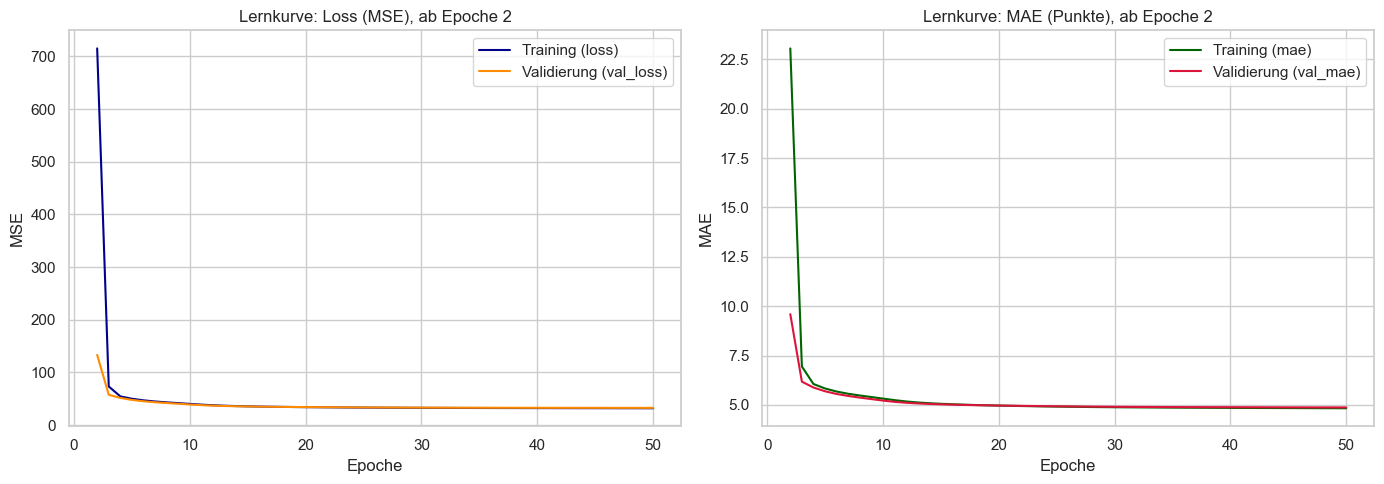

In [15]:
# Lernkurven der Baseline: Trainings- vs. Validierungsfehler über die Epochen
# Hinweis: Der große Fehler-Absturz in Epoche 1 würde die Y-Achse dominieren und die
# eigentlich interessante Feinkonvergenz unsichtbar machen. Daher wird bewusst erst ab
# Epoche 2 geplottet (die vollständige Historie bleibt in `history.history` erhalten).

hist = history.history
start = 1  # 0-basierter Index: überspringt Epoche 1

# X-Achse direkt an den Slice koppeln: Epoche 2 bis Ende
epochs_range = range(2, len(hist['loss']) + 1)   # explizit: ab Epoche 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Links: Loss (MSE)
axes[0].plot(epochs_range, hist['loss'][start:],     label='Training (loss)',        color='darkblue')
axes[0].plot(epochs_range, hist['val_loss'][start:], label='Validierung (val_loss)', color='darkorange')
axes[0].set_title('Lernkurve: Loss (MSE), ab Epoche 2')
axes[0].set_xlabel('Epoche'); axes[0].set_ylabel('MSE'); axes[0].legend()

# Rechts: MAE
axes[1].plot(epochs_range, hist['mae'][start:],     label='Training (mae)',         color='darkgreen')
axes[1].plot(epochs_range, hist['val_mae'][start:], label='Validierung (val_mae)',  color='crimson')
axes[1].set_title('Lernkurve: MAE (Punkte), ab Epoche 2')
axes[1].set_xlabel('Epoche'); axes[1].set_ylabel('MAE'); axes[1].legend()

plt.tight_layout(); plt.show()

# Lesart: Beide Kurven dicht beieinander => kein Overfitting (kein Auswendiglernen)

### 2. Numerische Gütemetriken: R², RMSE, MAE (auf `X_val`)

In [16]:
y_val_pred = baseline_model.predict(X_val, verbose=0).flatten()

def _metrics(y_true, y_pred):
    return (mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)),
            r2_score(y_true, y_pred))

# Rohe Vorhersagen
mae_val, rmse_val, r2_val = _metrics(y_val_reg, y_val_pred)

# Target-Ceiling: Ein Prozent-Score liegt per Definition in [0, 100].
# Vorhersagen außerhalb dieses Bereichs sind fachlich unmöglich (daher clippen).
y_val_pred_clip = np.clip(y_val_pred, 0, 100)
mae_c, rmse_c, r2_c = _metrics(y_val_reg, y_val_pred_clip)

print("Baseline-Metriken auf dem Validierungsset (X_val)")
print(f"                    roh     geclippt[0,100]")
print(f"  MAE  (Punkte) : {mae_val:7.3f}    {mae_c:7.3f}")
print(f"  RMSE (Punkte) : {rmse_val:7.3f}    {rmse_c:7.3f}")
print(f"  R\u00b2            : {r2_val:7.3f}    {r2_c:7.3f}")
print("\nHinweis: Das Clipping korrigiert nur unmögliche Vorhersagen > 100 (Target-Ceiling).")

Baseline-Metriken auf dem Validierungsset (X_val)
                    roh     geclippt[0,100]
  MAE  (Punkte) :   4.871      4.864
  RMSE (Punkte) :   5.710      5.705
  R²            :   0.909      0.909

Hinweis: Das Clipping korrigiert nur unmögliche Vorhersagen > 100 (Target-Ceiling).


### 3. Diagnoseplots: Vorhersage vs. Realität & Residuen

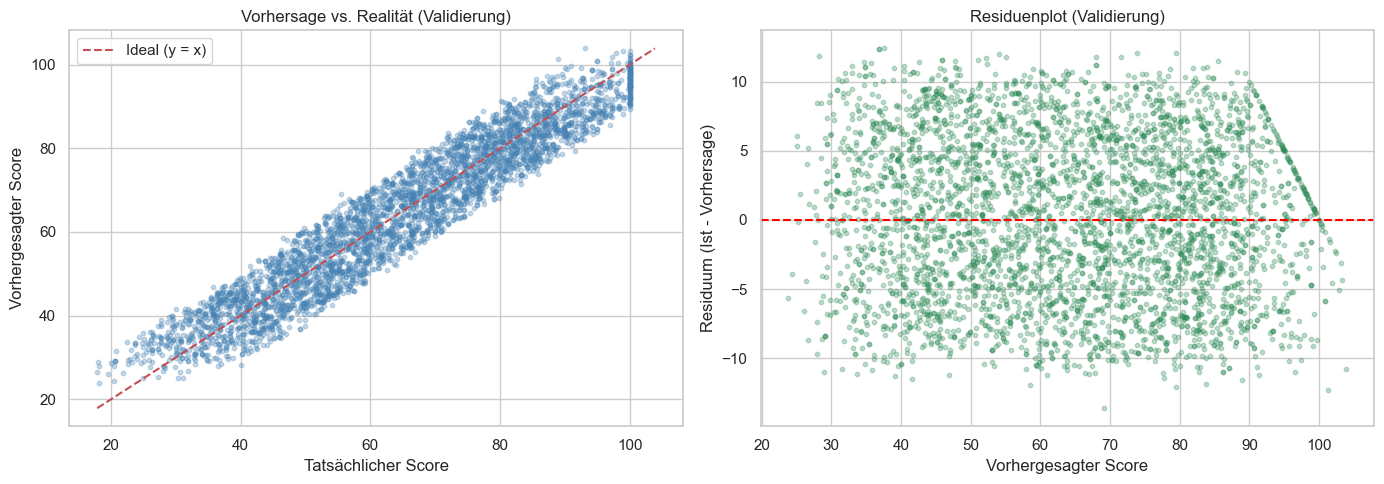

Mittleres Residuum          :   0.191  (nahe 0 = kein systematischer Bias)
Standardabweichung Residuen :   5.707


In [17]:
# Zwei Diagnoseplots auf dem Validierungsset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Links: Vorhersage vs. Realität
axes[0].scatter(y_val_reg, y_val_pred, alpha=0.3, s=10, color='steelblue')
lims = [min(y_val_reg.min(), y_val_pred.min()), max(y_val_reg.max(), y_val_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Ideal (y = x)')
axes[0].set_xlabel('Tatsächlicher Score'); axes[0].set_ylabel('Vorhergesagter Score')
axes[0].set_title('Vorhersage vs. Realität (Validierung)'); axes[0].legend()

# Rechts: Residuenplot (Validierung)
# Residuum: Differenz aus tatsächlichen und vorhergesagten Wert eines Datenpunkts
residuals = y_val_reg - y_val_pred
axes[1].scatter(y_val_pred, residuals, alpha=0.3, s=10, color='seagreen')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Vorhergesagter Score'); axes[1].set_ylabel('Residuum (Ist - Vorhersage)')
axes[1].set_title('Residuenplot (Validierung)')

plt.tight_layout(); plt.show()

print(f"Mittleres Residuum          : {residuals.mean():7.3f}  (nahe 0 = kein systematischer Bias)")
print(f"Standardabweichung Residuen : {residuals.std():7.3f}")

## Interpretation der Baseline-Ergebnisse

Die obigen Auswertungen lassen sich wie folgt lesen (für die exakten Zahlen: siehe Code-Ausgaben):

* **Kein Overfitting:** Trainings- und Validierungskurve verlaufen dicht beieinander, der Validierungsfehler steigt nicht an. Das Modell lernt allgemeingültige Muster, statt die Trainingsdaten auswendig zu lernen.

* **Hohe Erklärkraft:** Ein R² um 0,90 bedeutet, dass das Modell rund 90 % der Varianz im `overall_score` erklärt, also weit mehr als eine naive Vorhersage des reinen Mittelwerts, die per Definition R² = 0 liefert. Bemerkenswert ist, dass bereits diese schlanke Baseline mit einer einzigen verborgenen Schicht diesen Wert erreicht. Der RMSE liegt nur knapp über dem MAE. Dieser geringe Abstand bestätigt, dass es keine dramatischen Ausreißer gibt, da sonst die quadratische Gewichtung den RMSE deutlich nach oben ziehen würde.

* **Kein systematischer Bias:** Im Residuenplot streuen die Punkte gleichmäßig um die Null-Linie, das mittlere Residuum liegt nahe 0. Es gibt keinen Score-Bereich, in dem das Modell systematisch zu hoch oder zu niedrig schätzt.

* **Sichtbare Reststreuung:** Im Scatterplot liegen die Punkte eng um die Ideallinie ($y = x$), aber mit einer nicht verschwindenden Streuung. Diese Reststreuung ist ein erster Hinweis auf eine strukturelle Grenze der Vorhersagbarkeit. Mehr dazu im Fazit (**Feature-Ceiling**). Ein Teil der Streuung ganz oben stammt zudem vom **Target-Ceiling**: 524 Studierende (2,1 %) sind bei exakt 100 gedeckelt. Das Clipping der Vorhersagen auf $[0, 100]$ entfernt fachlich unmögliche Werte über 100 und senkt MAE und RMSE minimal.

**Konsequenz für das weitere Vorgehen:** Die Baseline ist stabil und frei von Overfitting. Ob sich der Fehler durch mehr Modellkapazität weiter senken lässt, wird als nächstes mit einem tiefen Netz (mit identischem Trainingsprotokoll) geprüft.

# Erweiterung: Deep Regression Model (Tiefes Neuronales Netz)

Nachdem die simple Baseline-Architektur ein stabiles Fundament ohne Overfitting bewiesen hat, erfolgt nun der logische nächste Schritt zur Minimierung des Vorhersagefehlers: die Erhöhung der Modellkomplexität durch ein tiefes neuronales Netz.

### Rationale für die Komplexitätssteigerung
Das Baseline-Modell (eine verborgene Schicht) erfasst primär direkte Zusammenhänge. Ein Datensatz mit 15 Features (z.B. Kombinationen aus Lernzeiten, Vorbildung und Anwesenheit) birgt jedoch komplexe Interaktionseffekte. Ein tiefes Netz kann diese hierarchisch entschlüsseln:
* Frühe, breite Schichten extrahieren grundlegende, feingranulare Muster aus den Rohdaten.
* Tiefere, schmalere Schichten kombinieren diese Muster zunehmend zu abstrakten, hochkomplexen Repräsentationen.

### Die neue Architektur (Trichter-Struktur)
Das neue Modell (`deep_model`) wird auf vier verborgene Schichten (Hidden Layers) erweitert. Die Anzahl der Units nimmt dabei systematisch ab, um die Informationsdichte pro Schicht zu erhöhen:

1. **Hidden Layer 1 (128 Units):** Bietet eine deutlich erhöhte Kapazität am Eingang, um alle 15 Input-Features detailliert abzutasten.
2. **Hidden Layer 2 (64 Units):** Beginnt mit der Verdichtung und Kombination der erkannten Basis-Muster.
3. **Hidden Layer 3 (32 Units):** Filtert die relevantesten Interaktionen heraus.
4. **Hidden Layer 4 (16 Units):** Bereitet die finale, hochkondensierte Information für die Ausgabeschicht vor.

Alle verborgenen Schichten nutzen weiterhin die **ReLU-Aktivierungsfunktion**, während die Ausgabeschicht linear bleibt, um den metrischen `overall_score` zu prädizieren.

### Methodische Entscheidung: maximal fairer Kapazitätsvergleich
Um den Effekt der reinen **Modellkapazität** zu isolieren, wird dieses Netz mit einem **identischen Trainingsprotokoll** wie die Baseline trainiert: gleicher Optimizer (`adam`, Standard-Lernrate 0,001), 50 Epochen, Batch-Size 32, dieselben Daten `X_tr` und `X_val`. Auf **Dropout** und **Early Stopping** wird bewusst verzichtet. Dadurch ist der **einzige** Unterschied zur Baseline die Tiefe und Breite des Netzes. Jede Leistungsänderung ist damit eindeutig auf die Kapazität zurückführbar und nicht auf Regularisierungs- oder Abbruchtricks. Eine milde Regularisierung wird erst in der finalen Feinabstimmung getestet.

In [ ]:
# 1. Input Layer
input_layer_deep = Input(shape=(num_features,), name="Input_Features_Deep")

# 2. Hidden Layers (4 Schichten, reine Trichterstruktur, OHNE Dropout)
# Bewusste Entscheidung für einen fairen Kapazitätsvergleich (Einziger Unterschied zur Baseline: mehr Schichten und Units)
hidden = Dense(units=128, activation='relu', name="Hidden_Layer_1")(input_layer_deep)
hidden = Dense(units=64,  activation='relu', name="Hidden_Layer_2")(hidden)
hidden = Dense(units=32,  activation='relu', name="Hidden_Layer_3")(hidden)
hidden = Dense(units=16,  activation='relu', name="Hidden_Layer_4")(hidden)

# 3. Output Layer (1 Unit, linear für Regression)
output_layer_deep = Dense(units=num_targets, activation='linear', name="Output_Score_Deep")(hidden)

# 4. Gesamtes Modell
deep_model = Model(inputs=input_layer_deep, outputs=output_layer_deep, name='Deep_Regression_FairCompare')

# Anzeige der Netzstruktur
deep_model.summary()

Model: "Deep_Regression_FairCompare"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Features_Deep             │ (None, 15)             │             0 │
│ (InputLayer)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_1 (Dense)          │ (None, 128)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_3 (Dense)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_4 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Score_Deep (Dense)       │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

## Training des tiefen Regressionsmodells

Um die Leistung der tieferen Architektur **objektiv** bewerten zu können, wird das Modell mit **exakt denselben** Trainingsparametern wie die Baseline trainiert. Dieses Vorgehen isoliert den Effekt der zusätzlichen Schichten und Units:

* **Optimizer:** `adam` (Standard-Lernrate 0,001), identisch zur Baseline
* **Epochen:** 50 (fest, **kein** Early Stopping)
* **Batch Size:** 32
* **Validierung:** nach jeder Epoche Abgleich mit dem separaten Validierungsset `X_val` und `y_val_reg` (**nicht** dem Testset!)

Ziel ist zu beobachten, ob die erhöhte Kapazität den Validierungsfehler (`val_mae`) gegenüber der Baseline **weiter senken** kann oder ob eine strukturelle Grenze erreicht wird. Die Trainingsergebnisse werden in `history_deep` gespeichert, um die Lernkurven später direkt mit der Baseline zu vergleichen.

In [19]:
# Identisches Setup zur Baseline: Standard-Adam (Lernrate 0,001), MSE-Loss, MAE-Metrik.
deep_model.compile(
    loss='mse',
    optimizer='adam',
    metrics=['mae']
)

In [20]:
# Fairer Vergleich: Exakt dasselbe Protokoll wie die Baseline(Vergleich durch Kapazität).

print("Starte Training des tiefen Modells (faires Protokoll, 50 Epochen)...")

history_deep = deep_model.fit(
    x=X_tr,
    y=y_tr_reg,
    epochs=50,
    batch_size=32,
    validation_data=(X_val, y_val_reg)
)

print("Training abgeschlossen!")

Starte Training des tiefen Modells (faires Protokoll, 50 Epochen)...
Epoch 1/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 360.8577 - mae: 10.8298 - val_loss: 42.8566 - val_mae: 5.4423
Epoch 2/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 39.4131 - mae: 5.2775 - val_loss: 35.9292 - val_mae: 5.0712
Epoch 3/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 36.0989 - mae: 5.0903 - val_loss: 34.3526 - val_mae: 4.9744
Epoch 4/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 34.9708 - mae: 5.0200 - val_loss: 33.8071 - val_mae: 4.9352
Epoch 5/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 34.2562 - mae: 4.9723 - val_loss: 33.4994 - val_mae: 4.9109
Epoch 6/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 33.7559 - mae: 4.9366 - val_loss: 33.2940 - val_mae: 4.8957
Epoch 7/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 33.3765 - mae: 4.9082 - val_loss: 33.0571 - val_mae: 4.8774
Epoch 8/50
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 33.0621 - mae: 4.8845 - val_l

### Lernkurven & Metriken des tiefen Netzes

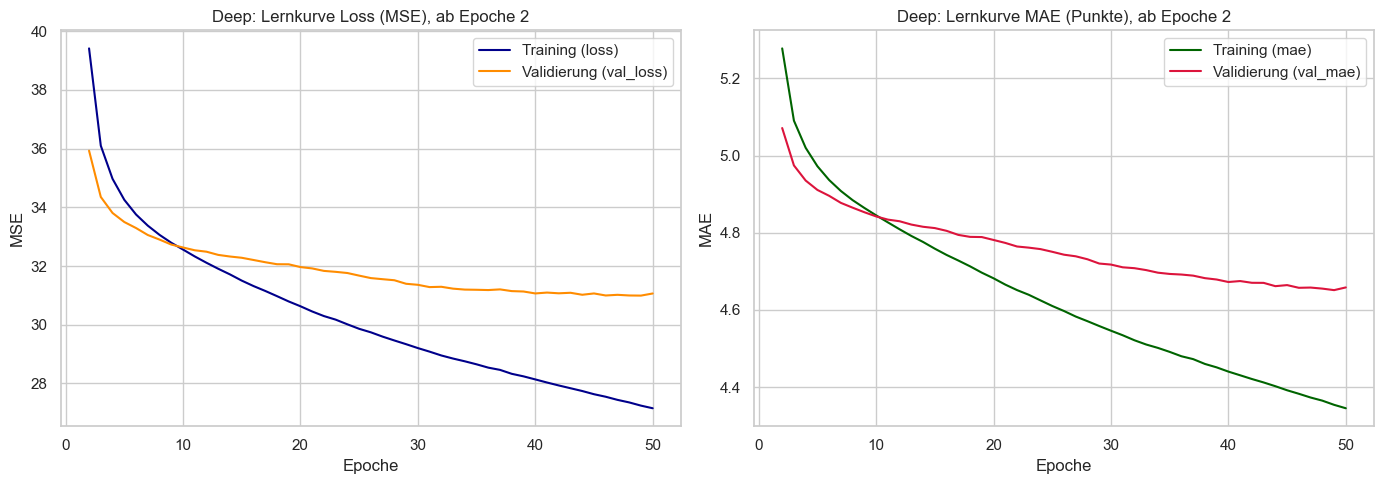

In [21]:
# Lernkurven des tiefen Netzes (ab Epoche 2, analog zur Baseline)
histd = history_deep.history
start = 1  # 0-basierter Index: überspringt Epoche 1
er = range(2, len(histd['loss']) + 1)  # X-Achse explizit ab Epoche 2

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(er, histd['loss'][start:],     label='Training (loss)',        color='darkblue')
axes[0].plot(er, histd['val_loss'][start:], label='Validierung (val_loss)', color='darkorange')
axes[0].set_title('Deep: Lernkurve Loss (MSE), ab Epoche 2')
axes[0].set_xlabel('Epoche'); axes[0].set_ylabel('MSE'); axes[0].legend()
axes[1].plot(er, histd['mae'][start:],     label='Training (mae)',         color='darkgreen')
axes[1].plot(er, histd['val_mae'][start:], label='Validierung (val_mae)',  color='crimson')
axes[1].set_title('Deep: Lernkurve MAE (Punkte), ab Epoche 2')
axes[1].set_xlabel('Epoche'); axes[1].set_ylabel('MAE'); axes[1].legend()
plt.tight_layout(); plt.show()

# Achtung: Ohne Dropout kann bei mehr Kapazität ein leichtes Auseinanderdriften
# von Training (niedriger) und Validierung (höher) auftreten, ein erstes Overfitting-Signal.

In [22]:
# Gütemetriken des tiefen Netzes auf demselben Validierungsset X_val
y_val_pred_deep = deep_model.predict(X_val, verbose=0).flatten()

mae_d, rmse_d, r2_d = _metrics(y_val_reg, y_val_pred_deep)             # roh
y_val_pred_deep_clip = np.clip(y_val_pred_deep, 0, 100)
mae_dc, rmse_dc, r2_dc = _metrics(y_val_reg, y_val_pred_deep_clip)     # geclippt

print("Deep-Model-Metriken auf dem Validierungsset (X_val)")
print(f"                    roh     geclippt[0,100]")
print(f"  MAE  (Punkte) : {mae_d:7.3f}    {mae_dc:7.3f}")
print(f"  RMSE (Punkte) : {rmse_d:7.3f}    {rmse_dc:7.3f}")
print(f"  R\u00b2            : {r2_d:7.3f}    {r2_dc:7.3f}")

Deep-Model-Metriken auf dem Validierungsset (X_val)
                    roh     geclippt[0,100]
  MAE  (Punkte) :   4.658      4.651
  RMSE (Punkte) :   5.574      5.569
  R²            :   0.913      0.913


## Direkter Vergleich: Baseline vs. tiefes Netz

Beide Modelle wurden unter **identischen Bedingungen** trainiert (gleicher Optimizer, 50 Epochen, Batch 32, dieselben Daten). Der einzige Unterschied ist die **Kapazität**. Die folgende Tabelle stellt die Leistung auf demselben Validierungsset `X_val` gegenüber.

Modell                              Params      MAE     RMSE       R2
---------------------------------------------------------------------
Baseline (1 Hidden Layer)              545    4.871    5.710   0.9090
Deep (4 Hidden, kein Dropout)        12929    4.658    5.574   0.9132
---------------------------------------------------------------------

Delta MAE (Deep - Baseline): -0.212 Punkte  (Deep besser)


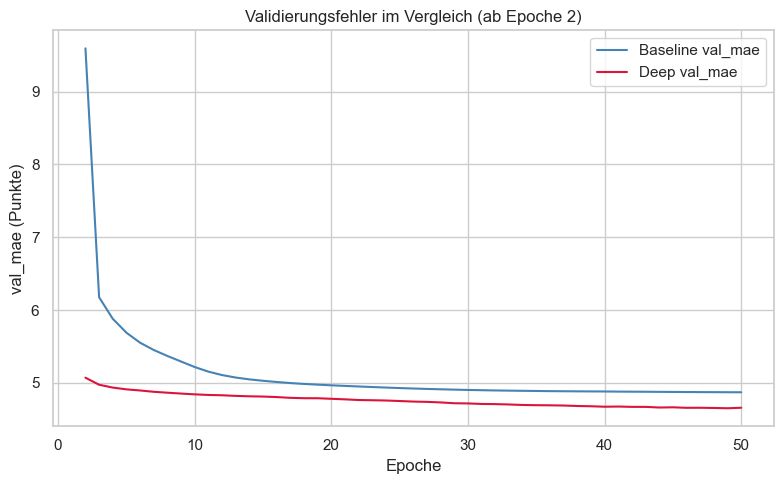

In [23]:
# Self-contained: beide Modelle auf X_val evaluieren und gegenüberstellen
yb = baseline_model.predict(X_val, verbose=0).flatten()
yd = deep_model.predict(X_val, verbose=0).flatten()
mae_b, rmse_b, r2_b = _metrics(y_val_reg, yb)
mae_dd, rmse_dd, r2_dd = _metrics(y_val_reg, yd)

print(f"{'Modell':<34}{'Params':>8}{'MAE':>9}{'RMSE':>9}{'R2':>9}")
print("-"*69)
print(f"{'Baseline (1 Hidden Layer)':<34}{baseline_model.count_params():>8}{mae_b:>9.3f}{rmse_b:>9.3f}{r2_b:>9.4f}")
print(f"{'Deep (4 Hidden, kein Dropout)':<34}{deep_model.count_params():>8}{mae_dd:>9.3f}{rmse_dd:>9.3f}{r2_dd:>9.4f}")
print("-"*69)
d_mae = mae_dd - mae_b
print(f"\nDelta MAE (Deep - Baseline): {d_mae:+.3f} Punkte  "
      f"({'Deep besser' if d_mae<0 else 'Baseline besser/gleich'})")

# Overlay der Validierungs-Lernkurven (val_mae) beider Modelle
plt.figure(figsize=(8,5))
plt.plot(range(2, len(history.history['val_mae'])+1),      history.history['val_mae'][1:],      label='Baseline val_mae', color='steelblue')
plt.plot(range(2, len(history_deep.history['val_mae'])+1), history_deep.history['val_mae'][1:], label='Deep val_mae',     color='crimson')
plt.title('Validierungsfehler im Vergleich (ab Epoche 2)')
plt.xlabel('Epoche'); plt.ylabel('val_mae (Punkte)'); plt.legend()
plt.tight_layout(); plt.show()

## Interpretation des Vergleichs

Die Antwort auf die zentrale Frage, ob mehr Modellkapazität einen niedrigeren Vorhersagefehler bringt, kann bejaht werden. Jedoch lohnt sich dieser deutlich erhöhte Aufwand bei einem so marginalen Unterschied kaum.

* **Kleiner, realer Gewinn:** Das tiefe Netz senkt den MAE von rund 4,87 auf rund 4,66 Punkte (R² von 0,909 auf 0,913). Das sind etwa 0,21 Punkte oder rund **4 % relative Verbesserung**, also messbar, aber gering.

* **Zu welchem Preis:** Dafür braucht es etwa **24-mal so viele Parameter** (12.929 gegenüber 545). Das Verhältnis von Aufwand zu Ertrag ist ausgesprochen ungünstig.

* **Beginnende Überanpassung:** Ohne Dropout fällt der Trainingsfehler (gegen Ende rund 4,4) deutlich unter den Validierungsfehler (rund 4,66). Diese Schere von etwa 0,3 Punkten existierte bei der Baseline praktisch nicht, dort lagen beide Kurven nahezu deckungsgleich. Das tiefe Netz beginnt also, Trainingsrauschen auswendig zu lernen, statt echtes neues Signal zu finden.

* **Warum so wenig Luft nach oben?** Der Zusammenhang ist überwiegend linear und wird bereits von einer einzigen Schicht fast vollständig erfasst. Das Merkmal `study_hours` ($r \approx 0{,}91$) dominiert so stark, dass tiefe nicht-lineare Muster nur noch Reste beitragen können.

**Zwischenfazit:** Damit steht eine faire und aussagekräftige Vergleichsbasis. Das Ergebnis, dass ein tiefes Netz den Fehler nur marginal senkt und dies mit beginnendem Overfitting erkauft, ist ein erstes deutliches Indiz für ein **Feature-Ceiling**, also für eine Grenze, die in den Daten und nicht im Modell liegt. Als Nächstes prüft die Hyperparameteroptimierung systematisch, ob eine andere Konfiguration diesen kleinen Vorsprung stabil und ohne Overfitting erreicht, oder ob die schlanke Baseline im Aufwand-Ertrag-Verhältnis das bessere Modell bleibt. Die vollständige Einordnung dieses Befunds erfolgt im Gesamtfazit, das mehrere unabhängige Belege zusammenführt.

# Hyperparameteroptimierung (manueller Grid-Search)

Bisher wurden zwei fest gewählte Architekturen verglichen (Baseline und ein tiefes Netz). Im Rahmen der **systematischen Hyperparameteroptimierung** kommt nun statt einer Blackbox-Library ein **transparenter, manueller Such-Loop** zum Einsatz. So bleibt jeder Schritt nachvollziehbar und unter vollständiger Kontrolle.

### Prinzip eines Grid-Search
Zunächst wird ein kleiner, klar abgegrenzter **Suchraum** definiert und anschließend **jede Kombination** systematisch ausprobiert. Jede Konfiguration wird unter identischen Bedingungen auf `X_tr` trainiert und auf `X_val` gemessen. Die Konfiguration mit dem niedrigsten Validierungsfehler „gewinnt".

### Suchraum
* **Architektur** (Anzahl und Breite der Hidden Layer): `[32]`, `[64,32]`, `[128,64,32]`, `[128,64,32,16]`, also von schlank bis tief.
* **Lernrate** des Adam-Optimizers: `0.001` und `0.0005`.

Das ergibt **8 Konfigurationen (= 4 × 2)**. Dropout bleibt hier bewusst außen vor (siehe separaten Test  in der finalen Feinabstimmung). Vor jedem Modell wird derselbe Seed gesetzt. Dadurch ist der Suchlauf reproduzierbar, und innerhalb einer Architektur unterscheiden sich die beiden Lernraten-Varianten ausschließlich durch die Lernrate, nicht durch die zufälligen Startgewichte.

In [24]:
# Manueller Grid-Search über Architektur x Lernrate
# Hinweis zur Ausführung des Codes: Dieser Loop trainiert 8 Modelle nacheinander und kann einige Minuten dauern.

# 1. Suchraum definieren
architekturen = {
    '1L [32]':          [32],
    '2L [64,32]':       [64, 32],
    '3L [128,64,32]':   [128, 64, 32],
    '4L [128,64,32,16]':[128, 64, 32, 16],
}
lernraten = [0.001, 0.0005]
SUCH_EPOCHEN = 40   # etwas kürzer als das finale Training, reicht zum Vergleichen

# 2. Hilfsfunktion: baut ein Modell aus einer Architektur-Liste
def baue_modell(units_liste):
    inp = Input(shape=(num_features,), name="in")
    x = inp
    for k, u in enumerate(units_liste):
        x = Dense(u, activation='relu', name=f"hidden_{k+1}")(x)
    out = Dense(num_targets, activation='linear', name="out")(x)
    return Model(inp, out)

# 3. Grid systematisch durchlaufen
ergebnisse = []
print("Starte Grid-Search über 8 Konfigurationen...\n")
for arch_name, units in architekturen.items():
    for lr in lernraten:
        tf.random.set_seed(SEED)                      # gleiche Startbedingung für fairen Vergleich
        modell = baue_modell(units)
        modell.compile(loss='mse', optimizer=Adam(learning_rate=lr), metrics=['mae'])
        h = modell.fit(X_tr, y_tr_reg, epochs=SUCH_EPOCHEN, batch_size=32,
                       validation_data=(X_val, y_val_reg), verbose=0)
        best_val_mae = min(h.history['val_mae'])                    # bester Wert über alle Epochen
        gap = h.history['val_mae'][-1] - h.history['mae'][-1]       # Overfitting-Schere (Ende)
        ergebnisse.append({'Architektur': arch_name, 'LR': lr, 'Params': modell.count_params(),
                           'best_val_MAE': round(best_val_mae, 3), 'Schere': round(gap, 3)})
        print(f"  {arch_name:20s} LR={lr:<7} -> best_val_MAE={best_val_mae:.3f}  Schere={gap:+.3f}")

# 4. Ergebnisse sortiert anzeigen
df_hpo = pd.DataFrame(ergebnisse).sort_values('best_val_MAE').reset_index(drop=True)
print("\nGrid-Search Ergebnisse (sortiert nach best_val_MAE)")
print(df_hpo.to_string(index=False))

# 5. Beste Konfiguration merken (siehe:Finalisierung)
best_row   = df_hpo.iloc[0]
best_units = architekturen[best_row['Architektur']]
best_lr    = float(best_row['LR'])
print(f"\nGewinner: {best_row['Architektur']} | LR={best_lr} | best_val_MAE={best_row['best_val_MAE']:.3f}")
print(f"-> best_units={best_units}, best_lr={best_lr} (für die Finalisierung gespeichert)")

Starte Grid-Search über 8 Konfigurationen...

  1L [32]              LR=0.001   -> best_val_MAE=4.894  Schere=+0.032
  1L [32]              LR=0.0005  -> best_val_MAE=4.979  Schere=+0.031
  2L [64,32]           LR=0.001   -> best_val_MAE=4.866  Schere=+0.199
  2L [64,32]           LR=0.0005  -> best_val_MAE=4.862  Schere=+0.139
  3L [128,64,32]       LR=0.001   -> best_val_MAE=4.772  Schere=+0.247
  3L [128,64,32]       LR=0.0005  -> best_val_MAE=4.767  Schere=+0.252
  4L [128,64,32,16]    LR=0.001   -> best_val_MAE=4.788  Schere=+0.265
  4L [128,64,32,16]    LR=0.0005  -> best_val_MAE=4.764  Schere=+0.260

Grid-Search Ergebnisse (sortiert nach best_val_MAE)
      Architektur     LR  Params  best_val_MAE  Schere
4L [128,64,32,16] 0.0005   12929         4.764   0.260
   3L [128,64,32] 0.0005   12417         4.767   0.252
   3L [128,64,32] 0.0010   12417         4.772   0.247
4L [128,64,32,16] 0.0010   12929         4.788   0.265
       2L [64,32] 0.0005    3137         4.862   0.139
   

## Auswahl & Bewertung des besten Modells

Das Gewinner-Setup aus dem Grid-Search wird nun **sauber nachtrainiert** (volle 50 Epochen, identisches Protokoll) und mit allen drei Metriken (MAE, RMSE, R²) auf `X_val` bewertet. So lässt sich das optimierte Modell direkt gegen Baseline und das erste tiefe Netz stellen.

In [25]:
# Bestes Modell aus dem Grid-Search sauber nachtrainieren (50 Epochen)
tf.random.set_seed(SEED)
best_model = baue_modell(best_units)
best_model.compile(loss='mse', optimizer=Adam(learning_rate=best_lr), metrics=['mae'])
history_best = best_model.fit(X_tr, y_tr_reg, epochs=50, batch_size=32,
                              validation_data=(X_val, y_val_reg), verbose=0)

# Metriken auf X_val
yb  = baseline_model.predict(X_val, verbose=0).flatten()
yd  = deep_model.predict(X_val, verbose=0).flatten()
ybs = best_model.predict(X_val, verbose=0).flatten()

rows = [('Baseline (1L)',        baseline_model, yb),
        ('Deep (4L)',   deep_model,     yd),
        ('Best-HPO (' + best_row['Architektur'] + ')', best_model, ybs)]

print(f"{'Modell':<28}{'Params':>8}{'MAE':>9}{'RMSE':>9}{'R2':>9}")
print('-'*63)
for name, mdl, yp in rows:
    mae_, rmse_, r2_ = _metrics(y_val_reg, yp)
    print(f"{name:<28}{mdl.count_params():>8}{mae_:>9.3f}{rmse_:>9.3f}{r2_:>9.4f}")
print('-'*63)

Modell                        Params      MAE     RMSE       R2
---------------------------------------------------------------
Baseline (1L)                    545    4.871    5.710   0.9090
Deep (4L)                      12929    4.658    5.574   0.9132
Best-HPO (4L [128,64,32,16])   12929    4.715    5.628   0.9115
---------------------------------------------------------------


## Interpretation der Hyperparameteroptimierung

Der Grid-Search hat systematisch 8 Konfigurationen geprüft. Die Ergebnisse lassen sich wie folgt einordnen (die konkreten Zahlen stehen in den Ausgaben oben):

* **Der Gewinner schlägt die Baseline nur knapp.** Selbst die beste gefundene Konfiguration senkt den Validierungsfehler gegenüber der einfachen Baseline nur um etwa ein Zehntel Punkt MAE. Das deckt sich exakt mit dem Feature-Ceiling-Befund aus dem Kapazitätsvergleich.
* **Tiefe und Lernrate sind zweitrangig.** Über den gesamten Suchraum hinweg bleibt der `best_val_MAE` in einem engen Band. Kein Hyperparameter bringt einen Sprung. Das ist ein weiterer Beleg, dass die Grenze in den Daten liegt und nicht in der Modellwahl.
* **Der Gewinner ist keine neue Architektur.** Das beste Setup ist `4L [128,64,32,16]`, also exakt die bereits getestete Architektur des tiefen Netzes. Der einzige Unterschied ist die auf 0,0005 halbierte Lernrate. Die systematische Suche hat somit kein besseres Netz gefunden, sondern das vorhandene tiefe Netz bestätigt und nur an einer einzigen Stellschraube minimal nachjustiert.
* **Sparsamkeit als Zusatzkriterium.** Der Loop wählt automatisch das Modell mit dem niedrigsten `best_val_MAE`. Da die Top-Konfigurationen aber praktisch gleichauf liegen, ergibt sich ein wichtiger Denkanstoß: Bei quasi identischem Fehler wäre das Modell mit **kleinerer Overfitting-Schere** und **weniger Parametern** eigentlich vorzuziehen. Genau diese Abwägung (schlanke Baseline gegen tiefes Gewinnermodell) wird in der finalen Prüfung aufgegriffen.

**Konsequenz für die Finalisierung:** Die Gewinner-Konfiguration (`best_units`, `best_lr`) wird als finales Modell übernommen. Sie wird anschließend per **Refit auf den vollen 80 %** (Training und Validierung zusammen) neu trainiert und **ein einziges Mal** auf dem bis dahin unberührten Testset `X_test` bewertet. Das ist die ehrliche Endnote. Anschließend folgt die Gesamtinterpretation inklusive Feature-Ceiling.

# Finalisierung des Regressionsmodells

In diesem abschließenden Teil wird aus den bisherigen Erkenntnissen das finale Modell abgeleitet und bewertet. Zunächst wird die zu Beginn angekündigte Regularisierung geprüft. Anschließend wird die finale Konfiguration per Refit auf dem vollen Trainingsblock (80 %) neu trainiert und ein einziges Mal auf dem Testset bewertet. Den Abschluss bilden eine genauere Analyse, was das Modell tatsächlich nutzt, sowie das Gesamtfazit.

> **Wichtig:** Ab dem finalen Refit wird zum ersten und einzigen Mal das Testset `X_test` verwendet. Bis hierhin erfolgte jede Modellauswahl ausschließlich auf dem Validierungsset `X_val`.

## Gegentest: milder Dropout auf der Gewinner-Architektur

Beim Kapazitätsvergleich wurde bewusst ohne Dropout gearbeitet, um allein den Effekt der Kapazität zu isolieren. Dabei zeigte sich eine leichte Overfitting-Schere (Trainingsfehler unter Validierungsfehler). Nun folgt die Prüfung auf Basis der Frage, ob ein milder Dropout (0,1) diese Schere, ohne den Validierungsfehler zu verschlechtern, schließt. Der Test läuft in der Auswahl-Welt (`X_tr` und `X_val`), damit `X_test` unberührt bleibt.

In [26]:
# Gewinner-Architektur mit mildem Dropout (0.1): Vergleich auf X_val
def baue_modell_dropout(units_liste, rate):
    inp = Input(shape=(num_features,), name="in"); x = inp
    for k, u in enumerate(units_liste):
        x = Dense(u, activation='relu', name=f"h{k+1}")(x)
        x = Dropout(rate, name=f"do{k+1}")(x)
    out = Dense(num_targets, activation='linear', name="out")(x)
    return Model(inp, out)

tf.random.set_seed(SEED)
model_do = baue_modell_dropout(best_units, 0.1)
model_do.compile(loss='mse', optimizer=Adam(learning_rate=best_lr), metrics=['mae'])
h_do = model_do.fit(X_tr, y_tr_reg, epochs=50, batch_size=32,
                    validation_data=(X_val, y_val_reg), verbose=0)

def _val_report(model, hist, label):
    yp = model.predict(X_val, verbose=0).flatten()
    mae_, rmse_, r2_ = _metrics(y_val_reg, yp)
    schere = hist.history['val_mae'][-1] - hist.history['mae'][-1]
    print(f"  {label:<26} MAE={mae_:.3f}  RMSE={rmse_:.3f}  R2={r2_:.4f}  Schere={schere:+.3f}")

print("Gegentest auf X_val: Gewinner-Architektur ohne und mit Dropout 0.1")
_val_report(best_model, history_best, "ohne Dropout (HPO-Gewinner)")
_val_report(model_do,   h_do,         "mit Dropout 0.1")
print("\nVergleich: val-MAE und Overfitting-Schere beider Varianten (Bewertung siehe folgende Entscheidung).")

Gegentest auf X_val: Gewinner-Architektur ohne und mit Dropout 0.1
  ohne Dropout (HPO-Gewinner) MAE=4.715  RMSE=5.628  R2=0.9115  Schere=+0.298
  mit Dropout 0.1            MAE=4.971  RMSE=5.873  R2=0.9037  Schere=-2.988

Vergleich: val-MAE und Overfitting-Schere beider Varianten (Bewertung siehe folgende Entscheidung).


### Entscheidung
Der Gegentest widerlegt die Erwartung: **Milder Dropout (0,1) senkt den Validierungsfehler nicht, sondern erhöht ihn**. Der val-MAE steigt von 4,715 auf etwa 4,971, das R² sinkt entsprechend. Die ohne Dropout beobachtete Overfitting-Schere ist mit rund 0,30 klein und beeinträchtigt die Validierungsleistung nicht. Eine Regularisierung bringt hier also keinen Mehrwert. Für das finale Modell wird daher die Gewinner-Architektur `[128, 64, 32, 16]` (LR = `best_lr`) **ohne Dropout** übernommen.

Hinweis zur Schere-Spalte: Für das Dropout-Modell ist die Schere nicht vergleichbar. Bei aktivem Dropout wird der Trainingsfehler künstlich erhöht, da im Training zufällig Neuronen abgeschaltet sind, während die Validierung ohne Dropout gemessen wird. Der stark negative Wert ist daher ein Messartefakt und kein Zeichen guter Generalisierung. Aussagekräftig ist allein der Validierungsfehler, und dieser spricht gegen Dropout.

Hinweis zur Reproduzierbarkeit: Durch den globalen Seed und `enable_op_determinism()` sind alle Ergebnisse auf derselben Hardware exakt reproduzierbar, auch die mit Dropout. Auf anderer Hardware können vor allem die Dropout-Ergebnisse minimal abweichen, da die Dropout-Masken eine zusätzliche Zufallsquelle darstellen. Ein finales Modell ohne Dropout liefert somit die stabilste berichtbare Endnote.

## Finales Modell: Refit auf den vollen 80 %

Jetzt wird das finale Modell auf **Training und Validierung zusammen** trainiert (die vollen 80 %, `X_train` und `y_train_reg`, 20.000 Zeilen). So fließt die gesamte verfügbare Trainingsinformation in das Endmodell. Der 3-Wege-Split hatte ausschließlich der Auswahl gedient. Während dieses finalen Trainings wird **keine** `validation_data` genutzt, denn der einzige verbleibende Prüfstein ist das Testset im nächsten Schritt.

In [27]:
# Finales Modell: Gewinner-Architektur OHNE Dropout, trainiert auf den vollen 80%
tf.random.set_seed(SEED)
final_model = baue_modell(best_units)
final_model.compile(loss='mse', optimizer=Adam(learning_rate=best_lr), metrics=['mae'])

print(f"Trainiere finales Modell auf {X_train.shape[0]} Zeilen (volle 80%)...")
history_final = final_model.fit(X_train, y_train_reg, epochs=50, batch_size=32, verbose=0)
print(f"Fertig. Finales Trainings-MAE: {history_final.history['mae'][-1]:.3f}")

Trainiere finales Modell auf 20000 Zeilen (volle 80%)...
Fertig. Finales Trainings-MAE: 4.411


## Einmalige, ehrliche Endbewertung auf dem Testset

Zum **ersten und einzigen Mal** erfolgt die Bewertung auf `X_test` (5.000 Studierende, die weder in Training noch in irgendeiner Modellauswahl vorkamen). Diese Zahlen sind die verteidigbare Endaussage über die Generalisierungsfähigkeit des Modells.

In [28]:
# EINMALIGE finale Bewertung auf dem ungesehenen Testset X_test
y_test_pred = final_model.predict(X_test, verbose=0).flatten()
mae_t,  rmse_t,  r2_t  = _metrics(y_test_reg, y_test_pred)
y_test_pred_c = np.clip(y_test_pred, 0, 100)
mae_tc, rmse_tc, r2_tc = _metrics(y_test_reg, y_test_pred_c)

print("FINALE Testset-Metriken (X_test, 5000 ungesehene Studierende)")
print(f"                    roh     geclippt[0,100]")
print(f"  MAE  (Punkte) : {mae_t:7.3f}    {mae_tc:7.3f}")
print(f"  RMSE (Punkte) : {rmse_t:7.3f}    {rmse_tc:7.3f}")
print(f"  R\u00b2            : {r2_t:7.3f}    {r2_tc:7.3f}")

FINALE Testset-Metriken (X_test, 5000 ungesehene Studierende)
                    roh     geclippt[0,100]
  MAE  (Punkte) :   4.930      4.916
  RMSE (Punkte) :   5.827      5.820
  R²            :   0.906      0.907


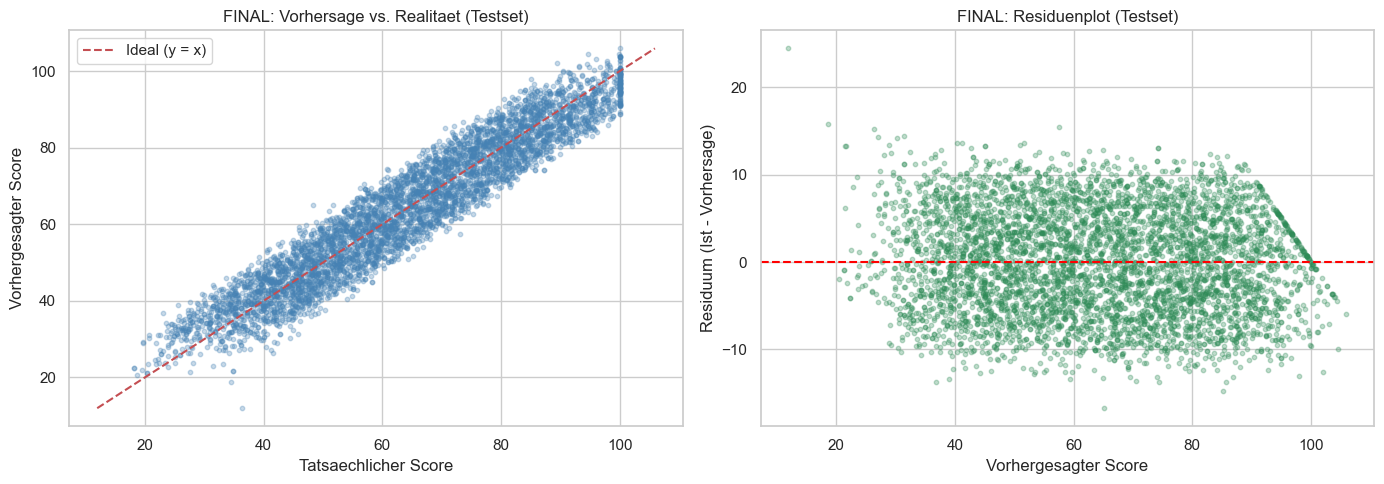

Mittleres Residuum (Test): -0.087  |  Std: 5.827


In [29]:
# Finale Diagnoseplots auf dem Testset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test_reg, y_test_pred, alpha=0.3, s=10, color='steelblue')
lims = [min(y_test_reg.min(), y_test_pred.min()), max(y_test_reg.max(), y_test_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=1.5, label='Ideal (y = x)')
axes[0].set_xlabel('Tatsaechlicher Score'); axes[0].set_ylabel('Vorhergesagter Score')
axes[0].set_title('FINAL: Vorhersage vs. Realitaet (Testset)'); axes[0].legend()

res_t = y_test_reg - y_test_pred
axes[1].scatter(y_test_pred, res_t, alpha=0.3, s=10, color='seagreen')
axes[1].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Vorhergesagter Score'); axes[1].set_ylabel('Residuum (Ist - Vorhersage)')
axes[1].set_title('FINAL: Residuenplot (Testset)')
plt.tight_layout(); plt.show()
print(f"Mittleres Residuum (Test): {res_t.mean():.3f}  |  Std: {res_t.std():.3f}")

### Interpretation der finalen Diagnoseplots

Die beiden Diagnoseplots auf dem Testset bestätigen die numerischen Metriken auch visuell:

* **Vorhersage vs. Realität (links):** Die Punktwolke liegt eng und symmetrisch um die Ideallinie ($y = x$), ohne Trichterform. Das Modell trifft über den gesamten Wertebereich gleichmäßig gut, was den hohen R²-Wert von $0{,}906$ grafisch untermauert. Die senkrechte Linie bei Score 100 entspricht dem Target-Ceiling, also den bei exakt 100 gedeckelten Fällen.

* **Residuenplot (rechts):** Über den Großteil des Wertebereichs streuen die Residuen als gleichmäßiges waagerechtes Band um die Nulllinie. Es gibt somit keinen systematischen Bias und keine übersehene Nichtlinearität. Das mittlere Residuum von $-0{,}087$ liegt praktisch bei null, es besteht also nur eine minimale und vernachlässigbare Tendenz zur Überschätzung. Die Standardabweichung von $5{,}827$ entspricht nahezu dem RMSE.

**Zur diagonalen Kante oben rechts:** Ab einem vorhergesagten Score von etwa 90 knickt die obere Punktwolke diagonal nach unten ab. Das ist kein Modellfehler, sondern eine direkte Folge des Target-Ceilings. Für alle bei 100 gedeckelten Studierenden gilt Residuum $= 100 - \text{Vorhersage}$. Je höher die Vorhersage, desto kleiner dieses Residuum, woraus zwangsläufig eine fallende Gerade mit Steigung $-1$ entsteht. Das Modell differenziert die Spitzengruppe also feiner, als es die harte Grenze bei 100 zulässt.

## Empirischer Beleg für den Feature-Ceiling

Die zentrale wissenschaftliche Erkenntnis dieser Arbeit lautet: Die Vorhersagegüte ist strukturell durch die **Daten** begrenzt, nicht durch das Modell. Der Beleg erfolgt direkt über eine einfache Gegenüberstellung. Die Leitfrage lautet: Wie weit kommt ein einziges Feature (`study_hours`) mit einem simplen linearen Modell im Vergleich zum finalen tiefen Netz auf allen 15 Features?

In [30]:
# Spaltenindex von 'study_hours' im Feature-Set bestimmen
sh_idx = list(X_encoded.columns).index('study_hours')

# Nur diese eine Spalte aus Train und Test ziehen (unskaliert, bei einem Feature ohne Einfluss auf die Güte)
Xtr_sh = X_train_raw.iloc[:, [sh_idx]].values
Xte_sh = X_test_raw.iloc[:, [sh_idx]].values

# Simples lineares Modell auf dem einzelnen Feature trainieren und auf dem Testset bewerten
lin = LinearRegression().fit(Xtr_sh, y_train_reg)
yte_lin = lin.predict(Xte_sh)
mae_lin, rmse_lin, r2_lin = _metrics(y_test_reg, yte_lin)

# Gegenüberstellung: Ein-Feature-Linearmodell gegen das finale tiefe Netz (15 Features)
print("Feature-Ceiling (Bewertung auf X_test)")
print(f"{'Modell':<38}{'MAE':>8}{'RMSE':>8}{'R2':>8}")
print(f"{'Lineare Reg. NUR study_hours':<38}{mae_lin:>8.3f}{rmse_lin:>8.3f}{r2_lin:>8.4f}")
print(f"{'Finales NN (15 Features, tief)':<38}{mae_t:>8.3f}{rmse_t:>8.3f}{r2_t:>8.4f}")

# Differenz beider Modelle: Mehrwert von 14 zusätzlichen Features plus Deep Learning
print(f"\nZugewinn durch 14 zusätzliche Features + Deep Learning:")
print(f"  R2:  +{r2_t - r2_lin:.3f}   |   MAE:  -{mae_lin - mae_t:.3f} Punkte")
print("\nDeutung: Ein einziges Feature erklärt bereits den Löwenanteil der Varianz.")

Feature-Ceiling (Bewertung auf X_test)
Modell                                     MAE    RMSE      R2
Lineare Reg. NUR study_hours             6.614   8.086  0.8199
Finales NN (15 Features, tief)           4.930   5.827  0.9065

Zugewinn durch 14 zusätzliche Features + Deep Learning:
  R2:  +0.087   |   MAE:  -1.684 Punkte

Deutung: Ein einziges Feature erklärt bereits den Löwenanteil der Varianz.


### Interpretation: Ein Feature gegen das volle Modell

Der Vergleich bringt den Feature-Ceiling direkt auf den Punkt:

* **Ein einziges Feature reicht fast aus.** Eine lineare Regression allein auf `study_hours` erreicht bereits ein $R^2$ von $0{,}82$. Von der gesamten Erklärkraft des finalen Netzes ($R^2 = 0{,}906$) liefert diese eine Variable somit rund 90 %.

* **Der Rest bringt wenig.** Die 14 weiteren Features zusammen mit der gesamten nichtlinearen Modellkomplexität heben das $R^2$ nur um $0{,}087$ und senken den MAE um $1{,}68$ Punkte (von $6{,}61$ auf $4{,}93$). Das ist ein realer, aber kleiner Zugewinn bei deutlich höherem Aufwand.

* **Die Grenze liegt in den Daten.** Wenn der Sprung vom einfachsten zum aufwendigsten Modell so gering ausfällt, ist das nutzbare Signal weitgehend ausgeschöpft. Weder ein zusätzliches Feature noch mehr Modelltiefe kann Information erzeugen, die in den Daten nicht steckt.

Damit ist der Feature-Ceiling empirisch belegt: Die Vorhersagegüte ist durch die verfügbaren Merkmale begrenzt, nicht durch die Wahl oder Größe des Modells.

## Feature-Wichtigkeit: Was nutzt das Netz wirklich? (Permutation Importance)

Der Feature-Ceiling zeigt, dass ein Feature (`study_hours`) den Großteil der Varianz trägt. Aber nutzt das *neuronale Netz* wirklich nur dieses eine Feature, oder gewichtet es weitere? Das beantwortet die **Permutation Importance**: Gezielt wird **ein** Feature zerstört (seine Werte werden zufällig durchmischt) und gemessen, **wie stark der Fehler dadurch steigt**. Ein großer Anstieg bedeutet, dass das Netz stark auf dieses Feature angewiesen war. Das Verfahren ist **modellbasiert**, im Gegensatz zur rein datenbasierten Korrelation aus der EDA, und funktioniert für jedes Black-Box-Modell.

*Analogie:* Wie beim Abdecken einzelner Zutaten in einem Rezept: Nacheinander wird je eine Zutat weggelassen, um zu sehen, wie sehr das Gericht darunter leidet. Die Zutat, deren Fehlen am meisten schadet, ist die wichtigste.

Basis-MAE (ungestört): 4.930
Permutation Importance (mittlerer MAE-Anstieg bei Zerstörung des Features)
study_hours                   15.646
attendance_percentage          3.171
gender_other                   0.340
gender_male                    0.294
study_method_mixed             0.202
study_method_notes             0.189
extra_activities_yes           0.166
study_method_online videos     0.165
school_type_public             0.164
study_method_textbook          0.164
study_method_group study       0.162
travel_time                    0.150
age                            0.118
parent_education               0.115
internet_access_yes            0.109


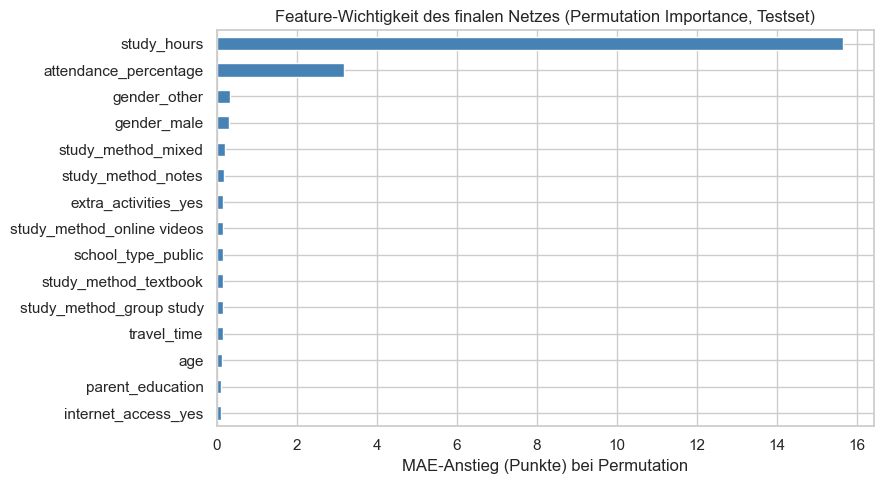

In [31]:
# Permutation Importance auf dem finalen Modell (Testset), manuell und ohne Zusatzpaket.
# Prinzip: EIN Feature zufällig durchmischen und messen, wie stark der MAE steigt.
rng = np.random.default_rng(SEED)
n_repeats = 5   # mehrfach mischen und mitteln für stabilere Werte

base_mae = mean_absolute_error(y_test_reg, final_model.predict(X_test, verbose=0).flatten())

importances = []
for j in range(X_test.shape[1]):
    anstiege = []
    for _ in range(n_repeats):
        X_perm = X_test.copy()
        X_perm[:, j] = rng.permutation(X_perm[:, j])          # nur Spalte j durchmischen
        mae_perm = mean_absolute_error(y_test_reg, final_model.predict(X_perm, verbose=0).flatten())
        anstiege.append(mae_perm - base_mae)                  # MAE-Anstieg gegenüber Basis
    importances.append(np.mean(anstiege))

imp = pd.Series(importances, index=X_encoded.columns).sort_values(ascending=False)
print(f"Basis-MAE (ungestört): {base_mae:.3f}")
print("Permutation Importance (mittlerer MAE-Anstieg bei Zerstörung des Features)")
print(imp.round(3).to_string())

# Visualisierung
plt.figure(figsize=(9, 5))
imp.sort_values().plot(kind='barh', color='steelblue')
plt.xlabel('MAE-Anstieg (Punkte) bei Permutation')
plt.title('Feature-Wichtigkeit des finalen Netzes (Permutation Importance, Testset)')
plt.tight_layout(); plt.show()

### Interpretation der Feature-Wichtigkeit

Das Ergebnis bestätigt und schärft den Feature-Ceiling aus **Modell-Sicht**:

* **`study_hours` dominiert mit riesigem Abstand.** Das zufällige Zerstören dieses Features lässt den MAE um mehr als das Vierfache ansteigen (von rund 4,9 auf etwa 20,6 Punkte). Das Netz stützt seine Vorhersage fast vollständig auf diese eine Variable.

* **`attendance_percentage` folgt als klarer, aber schwächerer Zweitfaktor** (MAE-Anstieg rund 3,2 Punkte). Bemerkenswert ist die Übereinstimmung mit der EDA: Dort war die Anwesenheit mit einer Korrelation von 0,29 bereits der Zweitplatzierte, und das bestätigt sich nun auch modellbasiert.

* **Alle übrigen Features sind nahezu bedeutungslos.** Elterliche Bildung, Geschlecht, Lernmethode, Schulweg und die restlichen Merkmale erzeugen beim Zerstören nur einen MAE-Anstieg zwischen rund 0,1 und 0,35 Punkten. Ihr Einfluss auf die Vorhersage ist somit vernachlässigbar.

* **Drei Belege, ein Bild.** Korrelation (EDA), Ein-Feature-Vergleich (Feature-Ceiling) und modellbasierte Permutation Importance stimmen überein. Die Vorhersagbarkeit steht und fällt mit `study_hours`.

Damit ist die Anforderung „Welche Features treiben die Vorhersage?" doppelt beantwortet: datenbasiert über die Korrelation und modellbasiert über die Permutation Importance.

## Gesamtfazit des Regressionsmodells

**Methodik.** Das Modell beruht auf einem 3-Wege-Split (64 % Training, 16 % Validierung, 20 % Test) mit einem Scaler, der ausschließlich auf den Trainingsdaten der Auswahl-Welt gefittet wurde (die Validierungsdaten flossen nicht in die Skalierung ein, um Data Leakage zu vermeiden). Jede Modellauswahl (Architektur, Lernrate, Dropout) erfolgte ausschließlich auf der Validierung, während das Testset bis zur finalen Bewertung unberührt blieb. Ein globaler Seed macht alle Läufe reproduzierbar.

**Ergebnisse.** Baseline (1 Schicht), tiefes Netz (4 Schichten) und das per Grid-Search optimierte Modell (ebenfalls 4 Schichten) liegen alle dicht beieinander (Validierungs-MAE rund 4,7 bis 4,9, R² rund 0,91). Das finale Modell erreicht auf dem ungesehenen Testset einen MAE von rund 4,9 Punkten (4,93 roh, 4,92 nach Clipping) und ein R² von rund 0,906. Es erklärt somit über 90 % der Varianz im `overall_score`. Der leicht höhere Wert gegenüber der Validierung (rund 4,7) entspricht dem normalen Unterschied zwischen einem zur Modellauswahl genutzten Validierungsset und einem völlig ungesehenen Testset.

**Wahl des finalen Modells.** Als finales Modell wird die per Grid-Search optimierte Konfiguration berichtet, also die Gewinner-Architektur `[128, 64, 32, 16]` ohne Dropout. Der Dropout wurde in einem eigenen Gegentest geprüft und verworfen, da er den Validierungsfehler nicht senkte, sondern leicht erhöhte. Damit ist die Hyperparameteroptimierung sichtbar umgesetzt. Da jedoch alle geprüften Modelle praktisch gleichauf liegen, wäre auch die schlanke Baseline eine ebenso gut begründbare, für den praktischen Einsatz sogar vorzuziehende Endwahl. Bei nahezu gleicher Leistung ist grundsätzlich das einfachere Modell zu bevorzugen, weil es weniger Parameter benötigt, schneller rechnet und leichter nachvollziehbar bleibt. Beide Wege sind methodisch verteidigbar, weshalb diese Abwägung hier bewusst transparent gemacht wird.

**Zentrale Erkenntnis: der Feature-Ceiling.** Diese Grenze ist über drei unabhängige Wege belegt: erstens der marginale Gewinn des tiefen Netzes gegenüber der Baseline, zweitens das enge Ergebnisband der systematischen Hyperparametersuche (alle acht Konfigurationen zwischen einem Validierungs-MAE von 4,76 und 4,98) und drittens der direkte Vergleich mit einem Ein-Feature-Modell. Ein einziger Prädiktor (`study_hours`, $r = 0{,}91$) erklärt bereits den Großteil der Zielvarianz. Die restlichen 14 Features und beliebige Modelltiefe heben das R² auf dem Testset nur von rund 0,82 auf rund 0,906 (MAE von rund 6,6 auf rund 4,9), also ein realer, aber begrenzter Zugewinn. Die Permutation Importance bestätigt dies aus Modell-Sicht: Das Zerstören von `study_hours` treibt den MAE von rund 4,9 auf über 20 Punkte, während alle übrigen Merkmale nahezu wirkungslos bleiben. Die Grenze der Vorhersagbarkeit liegt somit in den Daten und nicht im Modell. Dies stellt daher ein methodisch valides und wissenschaftlich wertvolles Ergebnis dar und kein Defizit.

**Nebenbefund: der Target-Ceiling.** Der `overall_score` ist bei 100 gedeckelt (524 Fälle, 2,1 %). Dieser Deckel wird in den Scatter- und Residuenplots als Randartefakt sichtbar, konkret als diagonale Kante im Residuenplot, und wird durch das Clipping der Vorhersagen auf $[0, 100]$ fachlich korrekt behandelt.

Das Regressionsmodell liefert damit eine verlässliche und reproduzierbare Vorhersage des `overall_score`. Zugleich benennt es seine eigene Grenze offen: Die erreichbare Genauigkeit hängt an wenigen, gut erfassbaren Merkmalen und nicht an der Komplexität des Netzes.

---

## Hinweis zur Verwendung von Künstlicher Intelligenz (KI)

Zur Unterstützung im Entstehungsprozess dieser Projektarbeit wurde **Claude Opus 4.8 (Anthropic)** als Hilfsmittel herangezogen. Die Nutzung erfolgte in folgenden Bereichen:

* **Planung und Strukturierung:** Unterstützung beim inhaltlichen Aufbau des Notebooks und der Modellstruktur, etwa bei der Reihenfolge der Abschnitte, dem roten Faden und der Gliederung der drei Modellstufen.
* **Programmierung:** Erläuterung technischer Aspekte des Python-Codes und Hilfestellung bei der Fehlersuche.
* **Formatierung:** Unterstützung bei der Konvertierung mathematischer Formeln und statistischer Kennzahlen in die **LaTeX-Schreibweise** für die Markdown-Zellen des Jupyter-Notebooks.
* **Analyse und Interpretation:** Unterstützung bei der Einordnung der statistischen Ergebnisse des Regressionsmodells sowie bei der sprachlichen Präzisierung der daraus abgeleiteten Schlussfolgerungen.

**Hinweis zur Eigenleistung:** Die inhaltliche Kontrolle, die Auswahl der relevanten Argumente sowie die abschließende Bewertung der Ergebnisse lagen zu jedem Zeitpunkt in der alleinigen Verantwortung des Erstellers dieser Projektarbeit. Sämtliche Text- und Code-Vorschläge der KI wurden eigenständig geprüft, angepasst und erst nach eigener Kontrolle in das Notebook übernommen. Die finale Entscheidung über jede Formulierung und jeden Analyseschritt lag beim Autor.

## - Mares Büchler